<a href="https://colab.research.google.com/github/phantom-beat/Proyecto-final/blob/main/SRGAN_Super_Resolucion_x4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aumentando la resolución de una imagen con GANs (SRGAN)

**Universidad Autónoma de Occidente — Redes Neuronales y Deep Learning**
Miniproyecto 3: Aplicación de arquitecturas de modelos generativos a la generación de imágenes

---

## Objetivo
Entrenar una **red generativa antagónica (GAN)** que reciba una imagen de **baja resolución (LR)** y genere su versión en **alta resolución (HR)**, con un factor de escala **×4**. El modelo se entrena sobre un **dataset personalizado**.

Se usa la arquitectura **SRGAN** (*Ledig et al., 2017, "Photo-Realistic Single Image Super-Resolution Using a Generative Adversarial Network"*), implementada desde cero en **TensorFlow / Keras**.

## Contenido
1. Configuración del entorno
2. Dataset
3. Generación de los pares LR → HR (modelo de degradación)
4. Arquitectura de la red (generador SRResNet + discriminador + pérdida perceptual VGG)
5. Fase 1: pre-entrenamiento del generador (SRResNet, pérdida MSE)
6. Fase 2: entrenamiento adversarial (SRGAN)
7. Validación: PSNR, SSIM, LPIPS, comparación visual, análisis cualitativo y rendimiento computacional
8. Uso del modelo con imágenes nuevas
9. Conclusiones

## 1. Configuración del entorno

In [ ]:
import os, glob, json, math, time, random, shutil, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

import tensorflow as tf
import keras
from keras import layers

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU disponible:", gpus if gpus else "NO -> activa la GPU en el entorno de ejecución")

SEED = 42
keras.utils.set_random_seed(SEED)                # semillas de Python, NumPy y TensorFlow
tf.config.experimental.enable_op_determinism()   # operaciones deterministas (resultados repetibles en GPU)
AUTOTUNE = tf.data.AUTOTUNE

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Hiperparámetros principales
Todos los parámetros del experimento están en esta celda para poder modificarlos fácilmente.

- `ESCALA = 4`: la imagen de salida tiene 4 veces más píxeles de ancho y de alto (16× más píxeles en total).
- `HR_SIZE = 96`: tamaño de los parches de alta resolución usados para entrenar (como en el artículo original). El parche LR correspondiente es de 24×24.
- `EPOCAS_PRE` y `EPOCAS_GAN`: número de **épocas** de cada fase. Una época es una pasada completa por el conjunto de entrenamiento (2 240 imágenes × 4 recortes aleatorios ÷ lotes de 16 = **560 iteraciones**). Al final de cada época se calculan las métricas de entrenamiento y validación y se guarda un checkpoint. Con los valores por defecto, el entrenamiento completo tarda aproximadamente **1 – 1.5 horas en una GPU T4**.

In [ ]:
# ---------------- Escala y tamaños ----------------
ESCALA   = 4            # factor de super-resolución
HR_SIZE  = 96           # parche de alta resolución para entrenar
LR_SIZE  = HR_SIZE // ESCALA
BATCH    = 16

# ---------------- Entrenamiento ----------------
EPOCAS_PRE  = 18        # fase 1: generador solo (MSE)
EPOCAS_GAN  = 18        # fase 2: entrenamiento adversarial
LR_PRE      = 1e-4      # tasa de aprendizaje fase 1
LR_GAN      = 1e-4      # tasa de aprendizaje fase 2 (baja a 1e-5 a mitad de la fase)
PESO_ADV    = 1e-3      # peso de la pérdida adversarial (valor del artículo SRGAN)
PESO_PIXEL  = 1.0       # pérdida MSE extra en fase 2 (mantiene colores y evita artefactos)

# ---------------- Datos ----------------
DEGRADACION_REALISTA = False  # True = además del downscale, agrega ruido y compresión JPEG
VAL_SIZE   = 192              # recorte central HR para validar durante el entrenamiento
TEST_MAX   = 512              # tamaño máximo del recorte HR en el conjunto de prueba

# ---------------- Guardado ----------------
GUARDAR_EN_DRIVE = True       # guarda checkpoints en Google Drive (sobreviven si se cae la sesión)

### Carpeta de checkpoints
Colab puede desconectarse. Por eso los pesos del modelo y el estado del entrenamiento se guardan periódicamente; si la sesión se cae, basta con volver a ejecutar todas las celdas y el entrenamiento **continúa desde el último checkpoint**.

In [ ]:
if GUARDAR_EN_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CKPT_DIR = "/content/drive/MyDrive/srgan_resultados_v2"
else:
    CKPT_DIR = "/content/srgan_checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(os.path.join(CKPT_DIR, "muestras"), exist_ok=True)

RUTA_ESTADO  = os.path.join(CKPT_DIR, "estado.json")
RUTA_G_PRE   = os.path.join(CKPT_DIR, "generador_srresnet.weights.h5")        # última época de la fase 1
RUTA_G_MEJOR = os.path.join(CKPT_DIR, "generador_srresnet_mejor.weights.h5")  # mejor época (PSNR de validación)
RUTA_G_GAN   = os.path.join(CKPT_DIR, "generador_srgan.weights.h5")
RUTA_D_GAN   = os.path.join(CKPT_DIR, "discriminador_srgan.weights.h5")

def cargar_estado():
    if os.path.exists(RUTA_ESTADO):
        with open(RUTA_ESTADO) as f:
            return json.load(f)
    return {"epoca_pre": 0, "epoca_gan": 0, "hist_pre": [], "hist_gan": []}

def guardar_estado(e):
    with open(RUTA_ESTADO, "w") as f:
        json.dump(e, f)
    # el historial también se guarda en CSV (una fila por época)
    for fase in ("pre", "gan"):
        if e[f"hist_{fase}"]:
            pd.DataFrame(e[f"hist_{fase}"]).to_csv(os.path.join(CKPT_DIR, f"historial_{fase}.csv"), index=False)

estado = cargar_estado()
print("Checkpoints en:", CKPT_DIR)
print("Épocas ya completadas -> fase 1:", estado["epoca_pre"], "| fase 2:", estado["epoca_gan"])

Mounted at /content/drive
Checkpoints en: /content/drive/MyDrive/srgan_resultados_v2
Épocas ya completadas -> fase 1: 0 | fase 2: 0


## 2. Dataset

In [ ]:
DATASET_DIR = "/content/dataset_personalizado"
NOMBRE_ZIP  = "srgan_dataset_personalizado.zip"
MANIFIESTO  = os.path.join(DATASET_DIR, "manifiesto.csv")
FUENTES     = ["div2k", "flores", "mascotas"]

UBICACIONES = [f"/content/drive/MyDrive/datasets/{NOMBRE_ZIP}",   # Google Drive
               f"/content/{NOMBRE_ZIP}"]                          # archivos de la sesión de Colab

if not os.path.exists(MANIFIESTO):
    zip_dataset = next((r for r in UBICACIONES if os.path.exists(r)), None)
    if zip_dataset is None:
        from google.colab import files
        print(f"No se encontró {NOMBRE_ZIP}; súbelo a continuación:")
        zip_dataset = "/content/" + next(iter(files.upload()))
    print("Descomprimiendo", zip_dataset, "...")
    with zipfile.ZipFile(zip_dataset) as z:
        z.extractall(DATASET_DIR)

manifiesto = pd.read_csv(MANIFIESTO)
rutas = [os.path.join(DATASET_DIR, a) for a in manifiesto["archivo"]]
print("Imágenes en el dataset personalizado:", len(rutas))

Descomprimiendo /content/drive/MyDrive/datasets/srgan_dataset_personalizado.zip ...
Imágenes en el dataset personalizado: 2800


### División entrenamiento / validación / prueba
La división **80 / 10 / 10 se hace por fuente (estratificada)**, de modo que los tres conjuntos contienen imágenes de DIV2K, flores y mascotas en la misma proporción. Así la validación y la prueba representan todo el dominio del dataset.

In [ ]:
def fuente_de(ruta):
    return os.path.basename(ruta).split("_")[0]

rutas_train, rutas_val, rutas_test = [], [], []
for f in FUENTES:
    grupo = sorted(r for r in rutas if fuente_de(r) == f)
    random.Random(SEED).shuffle(grupo)
    n_eval = max(5, int(0.1 * len(grupo)))
    rutas_test  += grupo[:n_eval]
    rutas_val   += grupo[n_eval:2 * n_eval]
    rutas_train += grupo[2 * n_eval:]
random.Random(SEED).shuffle(rutas_val)               # mezcla las fuentes en la validación

division = pd.DataFrame({nombre: pd.Series([fuente_de(r) for r in lista]).value_counts()
                         for nombre, lista in [("entrenamiento", rutas_train), ("validación", rutas_val),
                                               ("prueba", rutas_test)]}).reindex(list(FUENTES))
division.loc["total"] = division.sum()
division

,entrenamiento,validación,prueba
div2k,640,80,80
flores,800,100,100
mascotas,800,100,100
total,2240,280,280


## 3. Generación de los pares LR → HR (modelo de degradación)

La super-resolución es un problema **supervisado con pares**: para cada imagen de alta resolución $I^{HR}$ se crea su versión de baja resolución $I^{LR}$ aplicando un **modelo de degradación**:

$$I^{LR} = \text{JPEG}_q\big(\,\downarrow_{4}^{\text{bicúbica}}(I^{HR}) + n\,\big)$$

- $\downarrow_4$: reducción bicúbica con antialiasing (×4). Es la degradación estándar en la literatura (SRGAN, EDSR, ESRGAN).
- $n$ (ruido gaussiano) y $\text{JPEG}_q$ (compresión): **solo si** `DEGRADACION_REALISTA = True`. Hacen que el modelo funcione mejor con fotos reales (celular, WhatsApp), a costa de un poco de PSNR.

**Aumento de datos (data augmentation)** en entrenamiento: de cada imagen se toman varios recortes aleatorios de 96×96, con volteo horizontal y rotaciones de 90°.

Todas las imágenes se manejan en el rango **[0, 1]**.

In [ ]:
def cargar(ruta):
    img = tf.io.read_file(ruta)
    img = tf.io.decode_jpeg(img, channels=3)
    return tf.image.convert_image_dtype(img, tf.float32)   # [0, 1]

def degradar(hr, h_lr, w_lr):
    """Crea la imagen LR a partir de la HR (modelo de degradación)."""
    lr = tf.image.resize(hr, (h_lr, w_lr), method="bicubic", antialias=True)
    lr = tf.clip_by_value(lr, 0.0, 1.0)
    if DEGRADACION_REALISTA:
        sigma = tf.random.uniform([], 0.0, 0.02)
        lr = tf.clip_by_value(lr + tf.random.normal(tf.shape(lr), stddev=sigma), 0.0, 1.0)
        lr = tf.image.adjust_jpeg_quality(lr, tf.random.uniform([], 60, 95, dtype=tf.int32))
    return lr

def recorte_entrenamiento(img):
    hr = tf.image.random_crop(img, (HR_SIZE, HR_SIZE, 3))
    hr = tf.image.random_flip_left_right(hr)
    hr = tf.image.rot90(hr, tf.random.uniform([], 0, 4, dtype=tf.int32))
    lr = degradar(hr, LR_SIZE, LR_SIZE)
    return tf.ensure_shape(lr, (LR_SIZE, LR_SIZE, 3)), hr

def par_validacion(ruta):
    hr = tf.image.resize_with_crop_or_pad(cargar(ruta), VAL_SIZE, VAL_SIZE)  # recorte central
    lr = degradar(hr, VAL_SIZE // ESCALA, VAL_SIZE // ESCALA)
    return tf.ensure_shape(lr, (VAL_SIZE // ESCALA, VAL_SIZE // ESCALA, 3)), hr

def par_prueba(ruta):
    hr = cargar(ruta)
    s = tf.shape(hr)
    h = tf.minimum(s[0], TEST_MAX) // ESCALA * ESCALA
    w = tf.minimum(s[1], TEST_MAX) // ESCALA * ESCALA
    hr = tf.image.resize_with_crop_or_pad(hr, h, w)
    return degradar(hr, h // ESCALA, w // ESCALA), hr

RECORTES_POR_IMAGEN = 4
ds_train = (tf.data.Dataset.from_tensor_slices(rutas_train)
            .shuffle(len(rutas_train), seed=SEED).repeat()
            .map(cargar, num_parallel_calls=AUTOTUNE)
            .flat_map(lambda img: tf.data.Dataset.from_tensors(img).repeat(RECORTES_POR_IMAGEN))
            .map(recorte_entrenamiento, num_parallel_calls=AUTOTUNE)
            .shuffle(256)
            .batch(BATCH, drop_remainder=True)
            .prefetch(AUTOTUNE))

ds_val  = (tf.data.Dataset.from_tensor_slices(rutas_val)
           .map(par_validacion, num_parallel_calls=AUTOTUNE).batch(8).cache())
ds_test = tf.data.Dataset.from_tensor_slices(rutas_test).map(par_prueba).batch(1)

PASOS_POR_EPOCA = len(rutas_train) * RECORTES_POR_IMAGEN // BATCH   # iteraciones por época

lr_ej, hr_ej = next(iter(ds_train))
print("Lote de entrenamiento -> LR:", lr_ej.shape, "| HR:", hr_ej.shape)
print(f"Una época = {len(rutas_train)} imágenes × {RECORTES_POR_IMAGEN} recortes / lote {BATCH} = {PASOS_POR_EPOCA} iteraciones")

Lote de entrenamiento -> LR: (16, 24, 24, 3) | HR: (16, 96, 96, 3)
Una época = 2240 imágenes × 4 recortes / lote 16 = 560 iteraciones


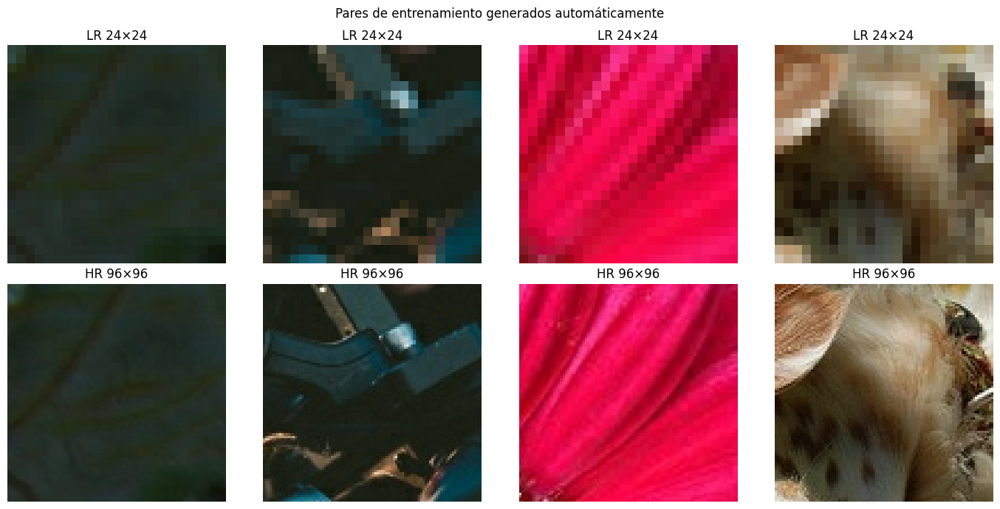

In [ ]:
# Visualización de pares (LR ampliada con vecino más cercano para que se vean los píxeles)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    axes[0, i].imshow(tf.image.resize(lr_ej[i], (HR_SIZE, HR_SIZE), method="nearest"))
    axes[0, i].set_title(f"LR {LR_SIZE}×{LR_SIZE}"); axes[0, i].axis("off")
    axes[1, i].imshow(hr_ej[i]); axes[1, i].set_title(f"HR {HR_SIZE}×{HR_SIZE}"); axes[1, i].axis("off")
plt.suptitle("Pares de entrenamiento generados automáticamente")
plt.tight_layout(); plt.show()

## 4. Arquitectura de la red

Una GAN tiene dos redes que compiten:
- **Generador $G$**: recibe la imagen LR y produce una imagen SR (super-resuelta) del tamaño HR.
- **Discriminador $D$**: recibe una imagen y decide si es una HR **real** o una SR **generada**.

$G$ intenta engañar a $D$, y $D$ intenta no ser engañado. Al final, $G$ aprende a generar detalles (texturas, bordes) que hacen que sus imágenes se vean como fotos reales de alta resolución.

### 4.1 Generador (SRResNet)

```
LR (h×w×3)
  └─ Conv 9×9, 64 + PReLU ───────────────┐  (conexión de salto global)
       └─ 16 × Bloque residual             │
             [Conv3×3 → PReLU → Conv3×3] + entrada
       └─ Conv 3×3, 64 ───────────────── (+)
  └─ Bloque de upsampling ×2:  Conv3×3,256 → PixelShuffle(×2) → PReLU
  └─ Bloque de upsampling ×2:  Conv3×3,256 → PixelShuffle(×2) → PReLU
  └─ Conv 9×9, 3  (= "detalle", inicializada en ceros)
SR (4h×4w×3) = recorte_[0,1]( Bicúbica×4(LR) + detalle )
```

Características del generador:
- **Bloques residuales**: cada bloque aprende solo la *diferencia* (residuo) que hay que sumar; esto permite redes profundas sin problemas de gradiente.
- **Toda la red trabaja en baja resolución** y solo al final se aumenta el tamaño, lo que la hace eficiente.
- **PixelShuffle (sub-pixel convolution)**: una convolución produce $64 \cdot 2^2 = 256$ canales y luego se reorganizan en un mapa con el doble de alto y ancho (`tf.nn.depth_to_space`). Evita los artefactos de "tablero de ajedrez" de las convoluciones transpuestas.
- **PReLU**: ReLU con pendiente negativa aprendible.
- Es **totalmente convolucional**: se entrena con parches de 24×24 pero funciona con imágenes de cualquier tamaño.
- *Modificación 1 — aprendizaje residual global*: la salida es `bicúbica(LR) + detalle`. La red solo aprende las altas frecuencias (bordes, texturas) que la interpolación no puede recuperar, idea tomada de VDSR (Kim et al., 2016). Como la última capa se inicializa en ceros, el modelo arranca exactamente con la calidad de la bicúbica y aprende a mejorarla, lo que acelera mucho la convergencia.
- *Modificación 2 — sin Batch Normalization*: se eliminaron las capas de Batch Normalization del generador, siguiendo a EDSR (2017) y ESRGAN (2018), que mostraron que BN produce artefactos en super-resolución y que quitarla mejora los resultados y reduce memoria.
- *Modificación 3 — salida acotada a [0, 1]*: la suma pasa por `ReLU(max_value=1)`, que recorta cada píxel al rango válido. Así, durante el entrenamiento las pérdidas y el discriminador reciben exactamente las mismas imágenes que se evalúan, y el discriminador no puede usar valores fuera de rango como pista para reconocer las imágenes generadas.

In [ ]:
@keras.saving.register_keras_serializable(package="srgan")
class PixelShuffle(layers.Layer):
    """Sub-pixel convolution: (h, w, c·r²) -> (h·r, w·r, c)."""
    def __init__(self, factor=2, **kwargs):
        super().__init__(**kwargs)
        self.factor = factor
    def call(self, x):
        return tf.nn.depth_to_space(x, self.factor)
    def get_config(self):
        return {**super().get_config(), "factor": self.factor}

def bloque_residual(x, filtros=64):
    y = layers.Conv2D(filtros, 3, padding="same")(x)
    y = layers.PReLU(shared_axes=[1, 2])(y)
    y = layers.Conv2D(filtros, 3, padding="same")(y)
    return layers.Add()([x, y])

@keras.saving.register_keras_serializable(package="srgan")
class AmpliacionBicubica(layers.Layer):
    """Amplía la imagen LR con interpolación bicúbica (sin parámetros entrenables)."""
    def __init__(self, factor=4, **kwargs):
        super().__init__(**kwargs)
        self.factor = factor
    def call(self, x):
        return tf.image.resize(x, tf.shape(x)[1:3] * self.factor, method="bicubic")
    def get_config(self):
        return {**super().get_config(), "factor": self.factor}

def construir_generador(n_bloques=16, filtros=64):
    entrada = layers.Input(shape=(None, None, 3), name="imagen_LR")
    x = layers.Conv2D(filtros, 9, padding="same")(entrada)
    x = layers.PReLU(shared_axes=[1, 2])(x)
    salto = x
    for _ in range(n_bloques):
        x = bloque_residual(x, filtros)
    x = layers.Conv2D(filtros, 3, padding="same")(x)
    x = layers.Add()([x, salto])
    for _ in range(int(math.log2(ESCALA))):        # 2 bloques de ×2 = ×4
        x = layers.Conv2D(filtros * 4, 3, padding="same")(x)
        x = PixelShuffle(2)(x)
        x = layers.PReLU(shared_axes=[1, 2])(x)
    # La red predice solo el DETALLE que le falta a la ampliación bicúbica.
    # Inicializada en ceros: al empezar, la salida es exactamente la bicúbica.
    detalle = layers.Conv2D(3, 9, padding="same", kernel_initializer="zeros", name="detalle")(x)
    suma = layers.Add(name="suma_residual")([AmpliacionBicubica(ESCALA)(entrada), detalle])
    salida = layers.ReLU(max_value=1.0, name="imagen_SR")(suma)   # recorta la salida a [0, 1]
    return keras.Model(entrada, salida, name="generador_SRResNet")

generador = construir_generador()
generador.summary(line_length=110)

Model: "generador_SRResNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                   ┃ Output Shape              ┃          Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ imagen_LR (InputLayer)         │ (None, None, None, 3)     │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ conv2d (Conv2D)                │ (None, None, None, 64)    │           15,616 │ imagen_LR[0][0]            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ p_re_lu (PReLU)                │ (None, None, None, 64)    │               64 │ conv2d[0][0]               │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)              │ (None, None, None, 64)    │           36,928 │ p_re_lu[0][0]              │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ p_re_lu_1 (PReLU)              │ (None, None, None, 64)    │               64 │ conv2d_1[0][0]             │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)              │ (None, None, None, 64)    │           36,928 │ p_re_lu_1[0][0]            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ add (Add)                      │ (None, None, None, 64)    │                0 │ p_re_lu[0][0],             │
│                                │                           │                  │ conv2d_2[0][0]             │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)              │ (None, None, None, 64)    │           36,928 │ add[0][0]                  │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ p_re_lu_2 (PReLU)              │ (None, None, None, 64)    │               64 │ conv2d_3[0][0]             │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ conv2d_4 (Conv2D)              │ (None, None, None, 64)    │           36,928 │ p_re_lu_2[0][0]            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ add_1 (Add)                    │ (None, None, None, 64)    │                0 │ add[0][0], conv2d_4[0][0]  │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ conv2d_5 (Conv2D)              │ (None, None, None, 64)    │           36,928 │ add_1[0][0]                │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ p_re_lu_3 (PReLU)              │ (None, None, None, 64)    │               64 │ conv2d_5[0][0]             │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ conv2d_6 (Conv2D)              │ (None, None, None, 64)    │           36,928 │ p_re_lu_3[0][0]            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ add_2 (Add)                    │ (None, None, None, 64)    │                0 │ add_1[0][0],               │
│                                │                           │                  │ conv2d_6[0][0]             │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ conv2d_7 (Conv2D)              │ (None, None, None, 64)    │           36,928 │ add_2[0][0]                │
├───

 Total params: 1,546,435 (5.90 MB)

 Trainable params: 1,546,435 (5.90 MB)

 Non-trainable params: 0 (0.00 B)

### 4.2 Discriminador

Red convolucional de clasificación binaria (real vs. generada) sobre parches de 96×96:

```
HR o SR (96×96×3)
  └─ Conv3×3,64 → LeakyReLU
  └─ [Conv3×3 → BN → LeakyReLU] × 7  con filtros 64,128,128,256,256,512,512
        (stride 2 en las capas pares → la imagen se reduce de 96 a 6)
  └─ Flatten → Dense 1024 → LeakyReLU → Dense 1  (logit: real / falso)
```
- Las convoluciones con *stride* 2 reducen la resolución en lugar de usar *pooling*.
- **LeakyReLU (α=0.2)** evita neuronas "muertas" y da gradientes útiles al generador.
- La salida es un *logit* (sin sigmoide); la sigmoide está incluida en la pérdida `BinaryCrossentropy(from_logits=True)`, que es numéricamente más estable.

In [ ]:
def bloque_d(x, filtros, stride, bn=True):
    x = layers.Conv2D(filtros, 3, strides=stride, padding="same")(x)
    if bn:
        x = layers.BatchNormalization()(x)
    return layers.LeakyReLU(0.2)(x)

def construir_discriminador():
    entrada = layers.Input(shape=(HR_SIZE, HR_SIZE, 3), name="imagen_HR_o_SR")
    x = layers.Rescaling(2.0, offset=-1.0)(entrada)          # [0,1] -> [-1,1]
    x = bloque_d(x, 64, 1, bn=False)
    x = bloque_d(x, 64, 2)
    x = bloque_d(x, 128, 1); x = bloque_d(x, 128, 2)
    x = bloque_d(x, 256, 1); x = bloque_d(x, 256, 2)
    x = bloque_d(x, 512, 1); x = bloque_d(x, 512, 2)
    x = layers.Flatten()(x)
    x = layers.Dense(1024)(x)
    x = layers.LeakyReLU(0.2)(x)
    salida = layers.Dense(1, name="logit_real")(x)
    return keras.Model(entrada, salida, name="discriminador")

discriminador = construir_discriminador()
discriminador.summary(line_length=110)

Model: "discriminador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                   ┃ Output Shape                        ┃             Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ imagen_HR_o_SR (InputLayer)                    │ (None, 96, 96, 3)                   │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ rescaling (Rescaling)                          │ (None, 96, 96, 3)                   │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv2d_36 (Conv2D)                             │ (None, 96, 96, 64)                  │               1,792 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ leaky_re_lu (LeakyReLU)                        │ (None, 96, 96, 64)                  │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv2d_37 (Conv2D)                             │ (None, 48, 48, 64)                  │              36,928 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ batch_normalization (BatchNormalization)       │ (None, 48, 48, 64)                  │                 256 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ leaky_re_lu_1 (LeakyReLU)                      │ (None, 48, 48, 64)                  │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv2d_38 (Conv2D)                             │ (None, 48, 48, 128)                 │              73,856 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ batch_normalization_1 (BatchNormalization)     │ (None, 48, 48, 128)                 │                 512 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ leaky_re_lu_2 (LeakyReLU)                      │ (None, 48, 48, 128)                 │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv2d_39 (Conv2D)                             │ (None, 24, 24, 128)                 │             147,584 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ batch_normalization_2 (BatchNormalization)     │ (None, 24, 24, 128)                 │                 512 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ leaky_re_lu_3 (LeakyReLU)                      │ (None, 24, 24, 128)                 │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv2d_40 (Conv2D)                             │ (None, 24, 24, 256)                 │             295,168 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ batch_normalization_3 (BatchNormalization)     │ (None, 24, 24, 256)                 │               1,024 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ leaky_re_lu_4 (LeakyReLU)                      │ (None, 24, 24, 256)                 │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv2d_41 (Conv2D)                             │ (None, 12, 12, 256)                 │             590,080 │
├───

 Total params: 23,569,217 (89.91 MB)

 Trainable params: 23,565,505 (89.90 MB)

 Non-trainable params: 3,712 (14.50 KB)

### 4.3 Funciones de pérdida

**Fase 1 — SRResNet (pre-entrenamiento):** pérdida de error cuadrático medio por píxel
$$\mathcal{L}_{MSE} = \frac{1}{N}\sum \big(I^{HR} - G(I^{LR})\big)^2$$
Maximiza el PSNR, pero produce imágenes algo **borrosas**: ante la incertidumbre, el modelo "promedia" todas las texturas posibles.

**Fase 2 — SRGAN:** pérdida perceptual del generador
$$\mathcal{L}_G = \underbrace{\mathcal{L}_{VGG}}_{\text{contenido}} + 10^{-3}\,\underbrace{\mathcal{L}_{adv}}_{\text{adversarial}} + \lambda_{pix}\,\mathcal{L}_{MSE}, \qquad \lambda_{pix} = 1$$

- **Pérdida de contenido VGG**: en vez de comparar píxeles, compara los *mapas de características* de una red **VGG19 pre-entrenada en ImageNet** (capa `block5_conv4`, la "VGG54" del artículo). Dos imágenes son "parecidas" si una red de visión las percibe parecidas, aunque los píxeles no coincidan exactamente.
- **Pérdida adversarial**: $\mathcal{L}_{adv} = -\log D(G(I^{LR}))$. Premia al generador cuando el discriminador cree que su imagen es real; es la que obliga a crear texturas realistas.
- **MSE por píxel**: término extra (no está en el artículo). Con un número limitado de pasos de entrenamiento, la pérdida VGG sola produce artefactos en cuadrícula y colores lavados; el término MSE ancla los colores y la estructura mientras la VGG y el discriminador agregan detalle.

**Discriminador:** entropía cruzada binaria clásica
$$\mathcal{L}_D = -\log D(I^{HR}) - \log\big(1 - D(G(I^{LR}))\big)$$

#### Justificación matemática de las pérdidas y de sus pesos

**MSE.** Para una imagen de $N$ valores, $\nabla_{\hat y}\,\mathcal{L}_{MSE} = \tfrac{2}{N}(\hat y - y)$: el gradiente corrige cada píxel en proporción a su error, por lo que fija colores, brillo y estructura de baja frecuencia. Además, como $\text{PSNR} = 10\log_{10}\!\big(1/\mathcal{L}_{MSE}\big)$ (imágenes en $[0,1]$), **minimizar el MSE equivale a maximizar el PSNR**; por eso SRResNet obtiene el mejor PSNR. Su inconveniente: ante varias texturas posibles para un mismo parche LR, el minimizador del MSE es su **promedio**, que se ve borroso.

**VGG (contenido).** $\mathcal{L}_{VGG} = \frac{1}{W H C}\sum \big(\phi_{5,4}(I^{HR}) - \phi_{5,4}(G(I^{LR}))\big)^2$, con $\phi_{5,4}$ los mapas de la capa `block5_conv4` divididos entre 12.75 (factor del artículo, que lleva esta pérdida a una magnitud comparable a la del MSE). Al comparar características de alto nivel en lugar de píxeles, tolera pequeños desplazamientos de textura y no castiga los detalles "plausibles" como lo hace el MSE.

**Adversarial.** El discriminador maximiza $\mathbb{E}[\log D(I^{HR})] + \mathbb{E}[\log(1 - D(G(I^{LR})))]$. Su óptimo es $D^*(x) = \frac{p_{HR}(x)}{p_{HR}(x) + p_G(x)}$ y, con $D^*$, el objetivo vale $-\log 4 + 2\,\mathrm{JSD}(p_{HR}\,\|\,p_G)$: entrenar al generador **reduce la divergencia de Jensen-Shannon** entre la distribución de imágenes reales y la de imágenes generadas, es decir, lo empuja a producir texturas con la estadística de las fotos reales. Se usa la forma *no saturante* $-\log D(G(I^{LR}))$ porque $\log(1 - D(G))$ tiene gradiente casi nulo cuando el discriminador gana ($D(G) \to 0$), que es justamente lo que ocurre en este entrenamiento (sección 6).

**Pesos.** Magnitudes promedio medidas en la fase 2 (historial por época): $\mathcal{L}_{VGG} \approx 0.146$, $\mathcal{L}_{adv} \approx 7.4$, $\mathcal{L}_{MSE} \approx 0.003$. Con los pesos usados, la composición de $\mathcal{L}_G \approx 0.157$ es:

| Término | Peso | Valor ponderado | % de $\mathcal{L}_G$ | Papel |
|---|---|---|---|---|
| VGG | 1 | ≈ 0.146 | ≈ 93 % | contenido y estructura perceptual |
| Adversarial | $10^{-3}$ | ≈ 0.007 | ≈ 5 % | texturas realistas de alta frecuencia |
| MSE | $\lambda_{pix} = 1$ | ≈ 0.003 | ≈ 2 % | ancla de color y baja frecuencia |

- $10^{-3}$ (valor del artículo) hace que el término adversarial aporte unos puntos porcentuales: suficiente para añadir textura, sin que el generador sacrifique el contenido por engañar al discriminador. Un peso mayor produce artefactos y alucinaciones; uno mucho menor deja solo la pérdida VGG (sin texturas realistas).
- El MSE pesa poco en el valor de $\mathcal{L}_G$, pero su gradiente actúa directamente sobre cada píxel y corrige los corrimientos de color que la VGG casi no penaliza.
- La sección 6 grafica la contribución de cada término época por época.

In [ ]:
vgg = keras.applications.VGG19(include_top=False, weights="imagenet", input_shape=(None, None, 3))
extractor_vgg = keras.Model(vgg.input, vgg.get_layer("block5_conv4").output, name="vgg54")
extractor_vgg.trainable = False

mse = keras.losses.MeanSquaredError()
bce = keras.losses.BinaryCrossentropy(from_logits=True)

def caracteristicas_vgg(img):
    # VGG espera imágenes en [0,255] con el preprocesamiento de ImageNet (BGR, media restada)
    x = keras.applications.vgg19.preprocess_input(img * 255.0)
    return extractor_vgg(x, training=False) / 12.75     # reescalado usado en el artículo SRGAN

def perdida_contenido(hr, sr):
    return mse(caracteristicas_vgg(hr), caracteristicas_vgg(sr))

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### 4.4 Diferencias con la SRGAN original

| Componente | SRGAN original (Ledig et al., 2017) | Este proyecto | Motivo |
|---|---|---|---|
| Datos de entrenamiento | 350 000 imágenes de ImageNet | 2 240 imágenes (dataset propio de 3 fuentes) | Requisito de dataset personalizado; tiempo de Colab |
| Pre-entrenamiento SRResNet | $10^6$ iteraciones, MSE, lr $10^{-4}$ | 10 080 iteraciones (18 épocas), MSE, lr $10^{-4}$ | Presupuesto de GPU (~1 h); se conserva la idea |
| Entrenamiento SRGAN | $10^5$ iter. con lr $10^{-4}$ + $10^5$ con $10^{-5}$ | 9 épocas con lr $10^{-4}$ + 9 con $10^{-5}$ (10 080 iter.) | Mismo esquema, escalado al presupuesto |
| Lote y parches | 16 parches HR de 96×96 | Igual | Conservado |
| Bloques del generador | 16 residuales con Batch Normalization | 16 residuales **sin** BN | BN causa artefactos en SR (EDSR, ESRGAN) |
| Salida del generador | Imagen SR directa | **Bicúbica + detalle** (última capa en ceros), **acotada a [0, 1]** | Aprendizaje residual global (VDSR): converge con pocas iteraciones; mismo rango en entrenamiento y evaluación |
| PReLU, PixelShuffle ×2 ×2, conv 9×9 | Sí | Igual | Conservado |
| Discriminador | 8 conv + BN + LeakyReLU(0.2), Dense 1024, sigmoide | Igual (logit + BCE *from_logits*, numéricamente más estable y equivalente) | Conservado |
| Pérdida del generador | $\mathcal{L}_{VGG54}/12.75 + 10^{-3}\mathcal{L}_{adv}$ | Igual **+ $\lambda_{pix}\mathcal{L}_{MSE}$** ($\lambda_{pix}=1$) | Estabiliza colores con entrenamiento corto |
| Rango de datos | LR en [0, 1], HR en [−1, 1] | LR y HR en [0, 1]; el discriminador reescala a [−1, 1] | Simplifica métricas y pérdidas |
| Optimizador | Adam, $\beta_1 = 0.9$ | Igual | Conservado |
| Evaluación | Set5, Set14, BSD100; PSNR, SSIM y MOS | Prueba propia (280 imágenes); PSNR, SSIM, **LPIPS** y análisis visual | Sin estudio con personas (MOS); LPIPS como medida perceptual automática |

### Funciones auxiliares de evaluación
- **Interpolación bicúbica**: la línea base (lo que haría cualquier editor de imágenes al ampliar).
- **MSE** (error cuadrático medio): la pérdida de validación de la fase 1; más bajo = mejor.
- **PSNR** (*Peak Signal-to-Noise Ratio*, en dB): mide la fidelidad píxel a píxel; más alto = mejor.
- **SSIM** (*Structural Similarity*, 0 a 1): mide similitud de estructura, luminancia y contraste; más alto = mejor.
- **Pérdida VGG** (perceptual): distancia entre las características VGG19 de la imagen generada y la real; más bajo = más parecida "a ojos de una red de visión".

Al final de **cada época** se calculan estas cuatro métricas sobre las 280 imágenes de validación.

In [ ]:
def bicubica(lr, tam_hr):
    tam_hr = [int(d) for d in tam_hr]
    return tf.clip_by_value(tf.image.resize(lr, tam_hr, method="bicubic"), 0.0, 1.0)

def predecir(modelo, lr):
    return tf.clip_by_value(modelo(lr, training=False), 0.0, 1.0)

def evaluar(modelo):
    """Métricas sobre el conjunto de validación (modelo=None -> interpolación bicúbica)."""
    m = {"mse": [], "psnr": [], "ssim": [], "vgg": []}
    for lr, hr in ds_val:
        sr = bicubica(lr, hr.shape[1:3]) if modelo is None else predecir(modelo, lr)
        m["mse"].append(tf.reduce_mean(tf.square(hr - sr), axis=[1, 2, 3]))
        m["psnr"].append(tf.image.psnr(hr, sr, 1.0))
        m["ssim"].append(tf.image.ssim(hr, sr, 1.0))
        m["vgg"].append(tf.fill([tf.shape(hr)[0]], perdida_contenido(hr, sr)))
    return {k: float(tf.reduce_mean(tf.concat(v, 0))) for k, v in m.items()}

base_val = evaluar(None)
print("Línea base (bicúbica) en validación -> MSE {mse:.5f} | PSNR {psnr:.2f} dB | "
      "SSIM {ssim:.4f} | VGG {vgg:.4f}".format(**base_val))

lr_fijo, hr_fijo = next(iter(ds_val))      # imágenes fijas para ver la evolución del entrenamiento

def guardar_muestra(modelo, nombre):
    sr = predecir(modelo, lr_fijo[:4])
    fila = np.concatenate([np.concatenate([bicubica(lr_fijo[i:i+1], hr_fijo.shape[1:3])[0],
                                           sr[i], hr_fijo[i]], axis=1) for i in range(4)], axis=0)
    plt.imsave(os.path.join(CKPT_DIR, "muestras", f"{nombre}.png"), np.clip(fila, 0, 1))

Línea base (bicúbica) en validación -> MSE 0.00371 | PSNR 26.49 dB | SSIM 0.7060 | VGG 0.2356


## 5. Fase 1: pre-entrenamiento del generador (SRResNet)

Entrenar la GAN desde cero es inestable: al inicio el generador produce ruido y el discriminador gana fácilmente. Por eso, igual que en el artículo, primero se entrena el generador **solo con MSE**. Así la fase adversarial parte de un generador que ya produce imágenes razonables y solo tiene que aprender a agregar detalles.

Optimizador: **Adam** con tasa de aprendizaje $10^{-4}$.

En cada época se muestra una barra de progreso con la pérdida y el PSNR de entrenamiento y, al final de la época:
- `loss` / `psnr`: MSE y PSNR promedio sobre los lotes de entrenamiento de la época.
- `val_loss` / `val_psnr` / `val_ssim`: MSE, PSNR y SSIM sobre el conjunto de validación.
- ★ marca la **mejor época** (mayor `val_psnr`); sus pesos se guardan aparte y son los que se usan como SRResNet final y como punto de partida de la fase 2.

In [ ]:
opt_pre = keras.optimizers.Adam(LR_PRE)

@tf.function
def paso_preentreno(lr, hr):
    with tf.GradientTape() as tape:
        sr = generador(lr, training=True)
        perdida = mse(hr, sr)
    grads = tape.gradient(perdida, generador.trainable_variables)
    opt_pre.apply_gradients(zip(grads, generador.trainable_variables))
    return perdida, tf.reduce_mean(tf.image.psnr(hr, tf.clip_by_value(sr, 0.0, 1.0), 1.0))

if estado["epoca_pre"] > 0 and os.path.exists(RUTA_G_PRE):
    generador.load_weights(RUTA_G_PRE)
    print("Reanudando fase 1 desde la época", estado["epoca_pre"] + 1)

print(f"Fase 1: {EPOCAS_PRE} épocas × {PASOS_POR_EPOCA} iteraciones (lote {BATCH}) | "
      f"bicúbica en validación: PSNR {base_val['psnr']:.2f} dB, SSIM {base_val['ssim']:.4f}\n")
it_train = iter(ds_train)
mejor = max(estado["hist_pre"], key=lambda h: h["val_psnr"], default=None)
for epoca in range(estado["epoca_pre"] + 1, EPOCAS_PRE + 1):
    print(f"Época {epoca}/{EPOCAS_PRE}")
    barra = keras.utils.Progbar(PASOS_POR_EPOCA, stateful_metrics=["loss", "psnr"])
    t0, perdidas, psnrs = time.time(), [], []
    for i in range(PASOS_POR_EPOCA):
        p, ps = paso_preentreno(*next(it_train))
        perdidas.append(float(p)); psnrs.append(float(ps))
        if (i + 1) % 20 == 0 or i + 1 == PASOS_POR_EPOCA:
            barra.update(i + 1, [("loss", np.mean(perdidas)), ("psnr", np.mean(psnrs))])
    val = evaluar(generador)
    fila = {"epoca": epoca, "iteraciones": epoca * PASOS_POR_EPOCA, "lr": LR_PRE,
            "loss": float(np.mean(perdidas)), "psnr": float(np.mean(psnrs)),
            "val_loss": val["mse"], "val_psnr": val["psnr"], "val_ssim": val["ssim"], "val_vgg": val["vgg"],
            "tiempo_s": time.time() - t0}
    estado["hist_pre"].append(fila)
    es_mejor = mejor is None or fila["val_psnr"] > mejor["val_psnr"]
    if es_mejor:
        mejor = fila; generador.save_weights(RUTA_G_MEJOR)
    generador.save_weights(RUTA_G_PRE)
    estado["epoca_pre"] = epoca; guardar_estado(estado)
    guardar_muestra(generador, f"fase1_ep{epoca:02d}")
    print(f"  loss {fila['loss']:.5f} - psnr {fila['psnr']:.2f} dB - val_loss {fila['val_loss']:.5f} - "
          f"val_psnr {fila['val_psnr']:.2f} dB - val_ssim {fila['val_ssim']:.4f} - "
          f"{fila['tiempo_s']:.0f}s{'  ★ mejor' if es_mejor else ''}\n")

print(f"Fase 1 completa. Mejor época: {mejor['epoca']} (val_psnr {mejor['val_psnr']:.2f} dB, "
      f"val_ssim {mejor['val_ssim']:.4f}) | tiempo total "
      f"{sum(h['tiempo_s'] for h in estado['hist_pre']) / 60:.1f} min")

Fase 1: 18 épocas × 560 iteraciones (lote 16) | bicúbica en validación: PSNR 26.49 dB, SSIM 0.7060

Época 1/18
560/560 ━━━━━━━━━━━━━━━━━━━━ 69s 123ms/step - loss: 0.0026 - psnr: 30.1540
  loss 0.00257 - psnr 30.15 dB - val_loss 0.00320 - val_psnr 27.41 dB - val_ssim 0.7397 - 79s  ★ mejor

Época 2/18
560/560 ━━━━━━━━━━━━━━━━━━━━ 55s 98ms/step - loss: 0.0023 - psnr: 30.8249
  loss 0.00232 - psnr 30.82 dB - val_loss 0.00309 - val_psnr 27.68 dB - val_ssim 0.7483 - 65s  ★ mejor

Época 3/18
560/560 ━━━━━━━━━━━━━━━━━━━━ 56s 100ms/step - loss: 0.0023 - psnr: 30.9809
  loss 0.00229 - psnr 30.98 dB - val_loss 0.00305 - val_psnr 27.78 dB - val_ssim 0.7502 - 66s  ★ mejor

Época 4/18
560/560 ━━━━━━━━━━━━━━━━━━━━ 57s 101ms/step - loss: 0.0022 - psnr: 31.1530
  loss 0.00223 - psnr 31.15 dB - val_loss 0.00305 - val_psnr 27.79 dB - val_ssim 0.7512 - 67s  ★ mejor

Época 5/18
560/560 ━━━━━━━━━━━━━━━━━━━━ 57s 102ms/step - loss: 0.0022 - psnr: 31.2437
  loss 0.00220 - psnr 31.24 dB - val_loss 0.00302 - val

## 6. Fase 2: entrenamiento adversarial (SRGAN)

En cada iteración:
1. El generador produce imágenes SR a partir de las LR.
2. El **discriminador** se actualiza para clasificar HR como reales (1) y SR como falsas (0).
3. El **generador** se actualiza con la pérdida perceptual (VGG + adversarial + MSE).

La fase parte de la **mejor época de la fase 1**. La tasa de aprendizaje pasa de $10^{-4}$ a $10^{-5}$ en la mitad de la fase (como en el artículo), para afinar los detalles.

Métricas por época:
- `L_G`: pérdida total del generador, con sus componentes `vgg` (contenido), `adv` (adversarial) y `pix` (MSE).
- `L_D`: pérdida del discriminador.
- `D(real)` y `D(falso)`: probabilidad promedio que asigna el discriminador a las imágenes reales y generadas. Si `D(falso)` se queda en ~0 todo el tiempo, el discriminador "ganó"; si ambos rondan 0.5 durante mucho tiempo, puede que el discriminador no esté aprendiendo.
- `val_psnr`, `val_ssim`, `val_vgg`: métricas de validación. El PSNR **puede bajar un poco** respecto a la fase 1 mientras la pérdida VGG baja: es el compromiso percepción-distorsión (sección 7).

In [ ]:
opt_g = keras.optimizers.Adam(LR_GAN)
opt_d = keras.optimizers.Adam(LR_GAN)

@tf.function
def paso_gan(lr, hr):
    with tf.GradientTape() as tape_g, tf.GradientTape() as tape_d:
        sr = generador(lr, training=True)
        logit_real  = discriminador(hr, training=True)
        logit_falso = discriminador(sr, training=True)

        p_contenido = perdida_contenido(hr, sr)
        p_adv       = bce(tf.ones_like(logit_falso), logit_falso)
        p_pixel     = mse(hr, sr)
        p_g = p_contenido + PESO_ADV * p_adv + PESO_PIXEL * p_pixel

        p_d = (bce(tf.ones_like(logit_real), logit_real) +
               bce(tf.zeros_like(logit_falso), logit_falso))

    grads_g = tape_g.gradient(p_g, generador.trainable_variables)
    grads_d = tape_d.gradient(p_d, discriminador.trainable_variables)
    opt_g.apply_gradients(zip(grads_g, generador.trainable_variables))
    opt_d.apply_gradients(zip(grads_d, discriminador.trainable_variables))
    return {"loss_g": p_g, "loss_vgg": p_contenido, "loss_adv": p_adv, "loss_pix": p_pixel, "loss_d": p_d,
            "d_real": tf.reduce_mean(tf.sigmoid(logit_real)),
            "d_falso": tf.reduce_mean(tf.sigmoid(logit_falso)),
            "psnr": tf.reduce_mean(tf.image.psnr(hr, tf.clip_by_value(sr, 0.0, 1.0), 1.0))}

if estado["epoca_gan"] > 0 and os.path.exists(RUTA_G_GAN):
    generador.load_weights(RUTA_G_GAN)
    discriminador.load_weights(RUTA_D_GAN)
    print("Reanudando fase 2 desde la época", estado["epoca_gan"] + 1)
else:
    generador.load_weights(RUTA_G_MEJOR)      # punto de partida: mejor época de la fase 1
    print("Iniciando fase 2 desde la mejor época de la fase 1")

print(f"Fase 2: {EPOCAS_GAN} épocas × {PASOS_POR_EPOCA} iteraciones (lote {BATCH})\n")
for epoca in range(estado["epoca_gan"] + 1, EPOCAS_GAN + 1):
    tasa = LR_GAN if epoca <= EPOCAS_GAN // 2 else LR_GAN / 10
    opt_g.learning_rate = tasa; opt_d.learning_rate = tasa
    print(f"Época {epoca}/{EPOCAS_GAN} (lr {tasa:.0e})")
    barra = keras.utils.Progbar(PASOS_POR_EPOCA, stateful_metrics=["L_G", "L_D", "D_real", "D_falso"])
    t0, acum = time.time(), []
    for i in range(PASOS_POR_EPOCA):
        acum.append({k: float(v) for k, v in paso_gan(*next(it_train)).items()})
        if (i + 1) % 20 == 0 or i + 1 == PASOS_POR_EPOCA:
            prom = {k: np.mean([a[k] for a in acum]) for k in acum[0]}
            barra.update(i + 1, [("L_G", prom["loss_g"]), ("L_D", prom["loss_d"]),
                                 ("D_real", prom["d_real"]), ("D_falso", prom["d_falso"])])
    val = evaluar(generador)
    fila = {"epoca": epoca, "iteraciones": epoca * PASOS_POR_EPOCA, "lr": tasa,
            **{k: float(np.mean([a[k] for a in acum])) for k in acum[0]},
            "val_loss": val["mse"], "val_psnr": val["psnr"], "val_ssim": val["ssim"], "val_vgg": val["vgg"],
            "tiempo_s": time.time() - t0}
    estado["hist_gan"].append(fila)
    generador.save_weights(RUTA_G_GAN); discriminador.save_weights(RUTA_D_GAN)
    estado["epoca_gan"] = epoca; guardar_estado(estado)
    guardar_muestra(generador, f"fase2_ep{epoca:02d}")
    print(f"  L_G {fila['loss_g']:.4f} (vgg {fila['loss_vgg']:.4f}, adv {fila['loss_adv']:.3f}, "
          f"pix {fila['loss_pix']:.5f}) - L_D {fila['loss_d']:.3f} - D(real) {fila['d_real']:.2f} - "
          f"D(falso) {fila['d_falso']:.2f} - val_psnr {fila['val_psnr']:.2f} dB - "
          f"val_ssim {fila['val_ssim']:.4f} - val_vgg {fila['val_vgg']:.4f} - {fila['tiempo_s']:.0f}s\n")

print(f"Fase 2 completa | tiempo total {sum(h['tiempo_s'] for h in estado['hist_gan']) / 60:.1f} min")

Iniciando fase 2 desde la mejor época de la fase 1
Fase 2: 18 épocas × 560 iteraciones (lote 16)

Época 1/18 (lr 1e-04)
560/560 ━━━━━━━━━━━━━━━━━━━━ 192s 343ms/step - L_G: 0.1561 - L_D: 0.8393 - D_real: 0.7815 - D_falso: 0.2144
  L_G 0.1561 (vgg 0.1495, adv 4.257, pix 0.00230) - L_D 0.839 - D(real) 0.78 - D(falso) 0.21 - val_psnr 27.16 dB - val_ssim 0.7252 - val_vgg 0.1785 - 202s

Época 2/18 (lr 1e-04)
560/560 ━━━━━━━━━━━━━━━━━━━━ 170s 304ms/step - L_G: 0.1572 - L_D: 0.3576 - D_real: 0.9259 - D_falso: 0.0727
  L_G 0.1572 (vgg 0.1464, adv 8.201, pix 0.00254) - L_D 0.358 - D(real) 0.93 - D(falso) 0.07 - val_psnr 26.72 dB - val_ssim 0.7093 - val_vgg 0.1848 - 181s

Época 3/18 (lr 1e-04)
560/560 ━━━━━━━━━━━━━━━━━━━━ 171s 305ms/step - L_G: 0.1601 - L_D: 0.3629 - D_real: 0.9356 - D_falso: 0.0647
  L_G 0.1601 (vgg 0.1489, adv 8.523, pix 0.00268) - L_D 0.363 - D(real) 0.94 - D(falso) 0.06 - val_psnr 26.51 dB - val_ssim 0.7048 - val_vgg 0.1872 - 181s

Época 4/18 (lr 1e-04)
560/560 ━━━━━━━━━━━━━━

### Métricas y curvas de entrenamiento

Resumen del entrenamiento, historial completo por época y gráficas:
- **Fase 1**: pérdida (MSE) de entrenamiento vs. validación, PSNR y SSIM por época. Si las curvas de entrenamiento y validación evolucionan juntas, el modelo generaliza (no hay sobreajuste).
- **Fase 2**: pérdidas del generador y del discriminador, salida del discriminador y métricas de validación.
- **Entrenamiento completo**: PSNR, SSIM y pérdida VGG de validación a lo largo de las dos fases, frente a la interpolación bicúbica.

Resumen del entrenamiento


,Fase 1 (SRResNet),Fase 2 (SRGAN),Bicúbica
Épocas,18,18,—
Iteraciones,10080,10080,—
Tiempo (min),20.2198,54.5027,—
Mejor época,17,—,—
val_psnr mejor época (dB),28.0872,—,—
val_ssim mejor época,0.7594,—,—
val_psnr última época (dB),28.0838,26.3394,26.4945
val_ssim última época,0.7584,0.6808,0.7060



Historial por época — Fase 1 (SRResNet)


,lr,loss,psnr,val_loss,val_psnr,val_ssim,val_vgg,tiempo_s
epoca,,,,,,,,
1,0.0001,0.00257,30.15400,0.00320,27.41420,0.73968,0.21674,78.57939
2,0.0001,0.00232,30.82490,0.00309,27.67827,0.74827,0.22055,64.81037
3,0.0001,0.00229,30.98094,0.00305,27.78345,0.75018,0.21818,65.97345
4,0.0001,0.00223,31.15298,0.00305,27.79199,0.75122,0.22157,67.13078
5,0.0001,0.00220,31.24368,0.00302,27.85807,0.75225,0.21850,67.45987
6,0.0001,0.00218,31.36375,0.00302,27.87049,0.75345,0.21923,66.82078
7,0.0001,0.00217,31.39211,0.00299,27.93267,0.75324,0.21723,66.62690
8,0.0001,0.00211,31.40658,0.00299,27.95526,0.75470,0.21502,66.66207
9,0.0001,0.00216,31.31013,0.00298,27.97793,0.75420,0.21776,67.39721



Historial por época — Fase 2 (SRGAN)


,lr,loss_g,loss_vgg,loss_adv,loss_pix,loss_d,d_real,d_falso,psnr,val_loss,val_psnr,val_ssim,val_vgg,tiempo_s
epoca,,,,,,,,,,,,,,
1,0.00010,0.15605,0.14950,4.25719,0.00230,0.83931,0.78153,0.21444,30.56199,0.00334,27.16495,0.72521,0.17852,202.37189
2,0.00010,0.15718,0.14644,8.20105,0.00254,0.35759,0.92591,0.07272,29.89977,0.00364,26.71856,0.70932,0.18476,180.76229
3,0.00010,0.16012,0.14891,8.52348,0.00268,0.36293,0.93559,0.06472,29.55240,0.00387,26.50852,0.70485,0.18722,181.01625
4,0.00010,0.15747,0.14644,8.36844,0.00267,0.36724,0.93643,0.06149,29.65386,0.00376,26.66944,0.70710,0.18451,180.73670
5,0.00010,0.15669,0.14548,8.47270,0.00273,0.44398,0.92330,0.08359,29.72360,0.00368,26.71967,0.70662,0.18048,181.23710
6,0.00010,0.15715,0.14630,8.13081,0.00273,0.33734,0.93807,0.06431,29.72292,0.00347,27.00315,0.71854,0.17721,180.83943
7,0.00010,0.16097,0.14949,8.71834,0.00276,0.29756,0.94107,0.06219,29.67507,0.00346,26.98259,0.71308,0.17549,180.27119
8,0.00010,0.15922,0.14739,9.09067,0.00274,0.28673,0.94143,0.06170,29.66199,0.00379,26.69157,0.70241,0.18174,179.83197
9,0.00010,0.15919,0.14788,8.41394,0.00290,0.32634,0.93004,0.07094,29.39088,0.00364,26.86298,0.71060,0.18274,180.44518


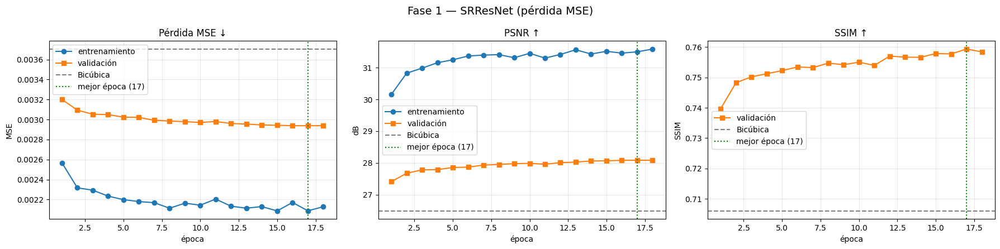

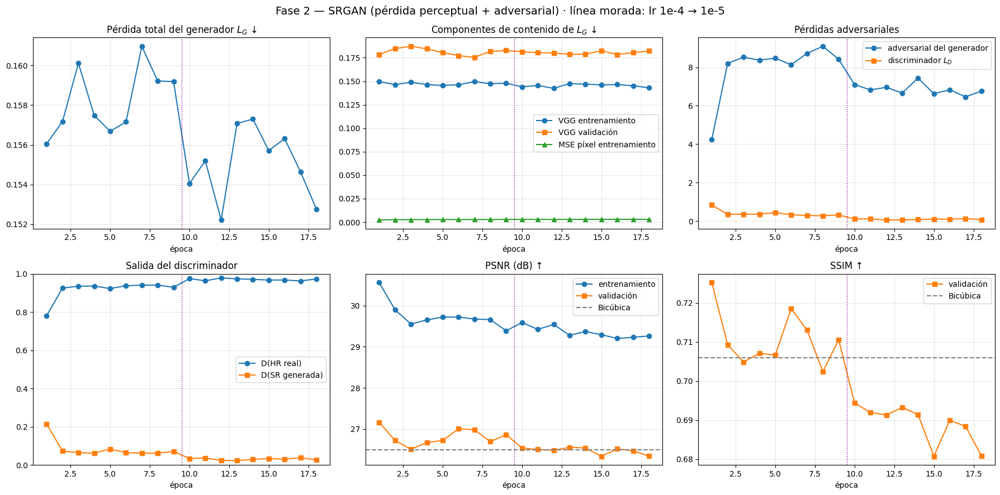

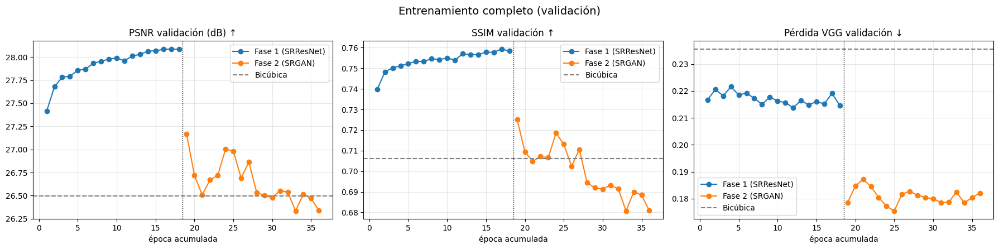

In [ ]:
h1 = pd.DataFrame(estado["hist_pre"]); h2 = pd.DataFrame(estado["hist_gan"])
mejor1 = h1.loc[h1["val_psnr"].idxmax()]

# ---------- Resumen ----------
resumen = pd.DataFrame({
    "Fase 1 (SRResNet)": {"Épocas": len(h1), "Iteraciones": int(h1["iteraciones"].max()),
                          "Tiempo (min)": h1["tiempo_s"].sum() / 60, "Mejor época": int(mejor1["epoca"]),
                          "val_psnr mejor época (dB)": mejor1["val_psnr"], "val_ssim mejor época": mejor1["val_ssim"],
                          "val_psnr última época (dB)": h1["val_psnr"].iloc[-1], "val_ssim última época": h1["val_ssim"].iloc[-1]},
    "Fase 2 (SRGAN)": {"Épocas": len(h2), "Iteraciones": int(h2["iteraciones"].max()),
                       "Tiempo (min)": h2["tiempo_s"].sum() / 60,
                       "val_psnr última época (dB)": h2["val_psnr"].iloc[-1], "val_ssim última época": h2["val_ssim"].iloc[-1]},
    "Bicúbica": {"val_psnr última época (dB)": base_val["psnr"], "val_ssim última época": base_val["ssim"]},
})
print("Resumen del entrenamiento")
display(resumen.map(lambda v: "—" if pd.isna(v) else (f"{int(v)}" if float(v).is_integer() else f"{v:.4f}")))

print("\nHistorial por época — Fase 1 (SRResNet)")
display(h1.set_index("epoca").drop(columns=["iteraciones"]).round(5))
print("\nHistorial por época — Fase 2 (SRGAN)")
display(h2.set_index("epoca").drop(columns=["iteraciones"]).round(5))

def marcar_bicubica(a, valor):
    a.axhline(valor, ls="--", c="gray", label="Bicúbica")

# ---------- Fase 1 ----------
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(h1["epoca"], h1["loss"], "o-", label="entrenamiento")
ax[0].plot(h1["epoca"], h1["val_loss"], "s-", label="validación")
marcar_bicubica(ax[0], base_val["mse"]); ax[0].set_title("Pérdida MSE ↓"); ax[0].set_ylabel("MSE")
ax[1].plot(h1["epoca"], h1["psnr"], "o-", label="entrenamiento")
ax[1].plot(h1["epoca"], h1["val_psnr"], "s-", label="validación")
marcar_bicubica(ax[1], base_val["psnr"]); ax[1].set_title("PSNR ↑"); ax[1].set_ylabel("dB")
ax[2].plot(h1["epoca"], h1["val_ssim"], "s-", c="C1", label="validación")
marcar_bicubica(ax[2], base_val["ssim"]); ax[2].set_title("SSIM ↑"); ax[2].set_ylabel("SSIM")
for a in ax:
    a.axvline(mejor1["epoca"], c="green", ls=":", label=f"mejor época ({int(mejor1['epoca'])})")
    a.set_xlabel("época"); a.grid(alpha=0.3); a.legend()
fig.suptitle("Fase 1 — SRResNet (pérdida MSE)", fontsize=14); plt.tight_layout(); plt.show()

# ---------- Fase 2 ----------
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
ax[0, 0].plot(h2["epoca"], h2["loss_g"], "o-"); ax[0, 0].set_title("Pérdida total del generador $L_G$ ↓")
ax[0, 1].plot(h2["epoca"], h2["loss_vgg"], "o-", label="VGG entrenamiento")
ax[0, 1].plot(h2["epoca"], h2["val_vgg"], "s-", label="VGG validación")
ax[0, 1].plot(h2["epoca"], h2["loss_pix"], "^-", label="MSE píxel entrenamiento")
ax[0, 1].set_title("Componentes de contenido de $L_G$ ↓"); ax[0, 1].legend()
ax[0, 2].plot(h2["epoca"], h2["loss_adv"], "o-", label="adversarial del generador")
ax[0, 2].plot(h2["epoca"], h2["loss_d"], "s-", label="discriminador $L_D$")
ax[0, 2].set_title("Pérdidas adversariales"); ax[0, 2].legend()
ax[1, 0].plot(h2["epoca"], h2["d_real"], "o-", label="D(HR real)")
ax[1, 0].plot(h2["epoca"], h2["d_falso"], "s-", label="D(SR generada)")
ax[1, 0].set_ylim(0, 1); ax[1, 0].set_title("Salida del discriminador"); ax[1, 0].legend()
ax[1, 1].plot(h2["epoca"], h2["psnr"], "o-", label="entrenamiento")
ax[1, 1].plot(h2["epoca"], h2["val_psnr"], "s-", label="validación")
marcar_bicubica(ax[1, 1], base_val["psnr"]); ax[1, 1].set_title("PSNR (dB) ↑"); ax[1, 1].legend()
ax[1, 2].plot(h2["epoca"], h2["val_ssim"], "s-", c="C1", label="validación")
marcar_bicubica(ax[1, 2], base_val["ssim"]); ax[1, 2].set_title("SSIM ↑"); ax[1, 2].legend()
for a in ax.flat:
    a.set_xlabel("época"); a.grid(alpha=0.3)
    a.axvline(EPOCAS_GAN // 2 + 0.5, c="purple", ls=":", lw=1)   # cambio de tasa de aprendizaje
fig.suptitle("Fase 2 — SRGAN (pérdida perceptual + adversarial) · línea morada: lr 1e-4 → 1e-5", fontsize=14)
plt.tight_layout(); plt.show()

# ---------- Entrenamiento completo ----------
total = pd.concat([h1.assign(fase="Fase 1 (SRResNet)"),
                   h2.assign(fase="Fase 2 (SRGAN)", epoca=h2["epoca"] + len(h1))])
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, col, base, titulo in [(ax[0], "val_psnr", base_val["psnr"], "PSNR validación (dB) ↑"),
                             (ax[1], "val_ssim", base_val["ssim"], "SSIM validación ↑"),
                             (ax[2], "val_vgg", base_val["vgg"], "Pérdida VGG validación ↓")]:
    for fase, g in total.groupby("fase"):
        a.plot(g["epoca"], g[col], "o-", label=fase)
    marcar_bicubica(a, base)
    a.axvline(len(h1) + 0.5, c="k", ls=":", lw=1)
    a.set_title(titulo); a.set_xlabel("época acumulada"); a.grid(alpha=0.3); a.legend()
fig.suptitle("Entrenamiento completo (validación)", fontsize=14); plt.tight_layout(); plt.show()

### Análisis de estabilidad del entrenamiento adversarial

Indicadores calculados a partir del historial de la fase 2:
- **Composición de $\mathcal{L}_G$**: contribución ponderada de cada término (VGG, adversarial, MSE) por época.
- **Equilibrio generador-discriminador**: $L_D$ y la brecha $D(\text{real}) - D(\text{falso})$. Una brecha cercana a 1 indica que el discriminador distingue casi siempre; cercana a 0, que el generador lo engaña o que el discriminador no aprende.
- **Variabilidad de la validación**: media y desviación estándar de las métricas antes y después de bajar la tasa de aprendizaje.

Contribución promedio de cada término a L_G (fase 2):


,Valor ponderado,% de L_G
VGG,0.1464,93.4670
Adversarial (×1e-3),0.0074,4.7419
MSE (×λ_pix),0.0028,1.7911



Estabilidad por tramo de la fase 2 (media y desviación estándar entre épocas):


lr 1e-4 (épocas 1–9)         lr 1e-5 (épocas 10–18)        
                              mean     std                   mean     std
PSNR val (dB)              26.8135  0.2052                26.4743  0.0823
SSIM val                    0.7109  0.0072                 0.6891  0.0050
VGG val                     0.1814  0.0038                 0.1803  0.0015
L_D                         0.4021  0.1702                 0.1010  0.0243
D(real)                     0.9170  0.0512                 0.9708  0.0054
D(falso)                    0.0840  0.0494                 0.0306  0.0055

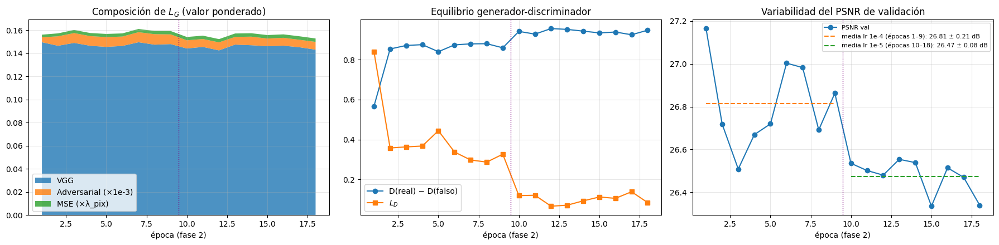

In [ ]:
contrib = pd.DataFrame({"VGG": h2["loss_vgg"], "Adversarial (×1e-3)": PESO_ADV * h2["loss_adv"],
                        "MSE (×λ_pix)": PESO_PIXEL * h2["loss_pix"]})
porcentaje = contrib.div(contrib.sum(axis=1), axis=0) * 100
print("Contribución promedio de cada término a L_G (fase 2):")
display(pd.DataFrame({"Valor ponderado": contrib.mean(), "% de L_G": porcentaje.mean()}).round(4))

mitad = EPOCAS_GAN // 2
columnas = {"val_psnr": "PSNR val (dB)", "val_ssim": "SSIM val", "val_vgg": "VGG val",
            "loss_d": "L_D", "d_real": "D(real)", "d_falso": "D(falso)"}
tramos = {f"lr 1e-4 (épocas 1–{mitad})": h2.iloc[:mitad], f"lr 1e-5 (épocas {mitad + 1}–{EPOCAS_GAN})": h2.iloc[mitad:]}
estabilidad = pd.concat({k: v[list(columnas)].rename(columns=columnas).agg(["mean", "std"]).T
                         for k, v in tramos.items()}, axis=1)
print("\nEstabilidad por tramo de la fase 2 (media y desviación estándar entre épocas):")
display(estabilidad.round(4))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].stackplot(h2["epoca"], contrib.T.values, labels=contrib.columns, alpha=0.8)
ax[0].set_title("Composición de $L_G$ (valor ponderado)"); ax[0].legend(loc="lower left")
ax[1].plot(h2["epoca"], h2["d_real"] - h2["d_falso"], "o-", label="D(real) − D(falso)")
ax[1].plot(h2["epoca"], h2["loss_d"], "s-", label="$L_D$")
ax[1].set_title("Equilibrio generador-discriminador"); ax[1].legend()
ax[2].plot(h2["epoca"], h2["val_psnr"], "o-", label="PSNR val")
for (k, v), c in zip(tramos.items(), ["C1", "C2"]):
    ax[2].hlines(v["val_psnr"].mean(), v["epoca"].min(), v["epoca"].max(), colors=c, ls="--",
                 label=f"media {k}: {v['val_psnr'].mean():.2f} ± {v['val_psnr'].std():.2f} dB")
ax[2].set_title("Variabilidad del PSNR de validación"); ax[2].legend(fontsize=8)
for a in ax:
    a.set_xlabel("época (fase 2)"); a.grid(alpha=0.3); a.axvline(mitad + 0.5, c="purple", ls=":", lw=1)
plt.tight_layout(); plt.show()

**Interpretación.**
- **No hubo divergencia ni colapso.** $\mathcal{L}_G$ se mantuvo entre 0.152 y 0.161 durante toda la fase 2, y la pérdida VGG de validación mejoró respecto a SRResNet (≈ 0.219 → 0.182): el generador siguió aprendiendo contenido perceptual.
- **El discriminador domina.** $D(\text{falso})$ cae de 0.21 en la primera época a ≈ 0.03 y $L_D$ baja de ≈ 0.40 (promedio con lr $10^{-4}$) a ≈ 0.10 (con lr $10^{-5}$): el discriminador distingue casi siempre las imágenes generadas. Gracias a la forma no saturante $-\log D(G)$, el generador sigue recibiendo gradiente adversarial ($\mathcal{L}_{adv} \approx 6.5$–$9$ desde la segunda época), y como ese término pesa ≈ 5 % de $\mathcal{L}_G$, el dominio del discriminador no desestabiliza al generador.
- **La reducción de la tasa de aprendizaje estabiliza.** Con lr $10^{-4}$ el PSNR de validación osciló entre 26.51 y 27.16 dB (desviación ≈ 0.21 dB); con lr $10^{-5}$ quedó entre 26.34 y 26.55 dB (desviación ≈ 0.08 dB). La desviación de $L_D$ también baja de 0.17 a 0.02.
- **Posibles mejoras de convergencia** (trabajo futuro): discriminador relativista (ESRGAN), normalización espectral en el discriminador, suavizado de etiquetas o tasas de aprendizaje distintas para $G$ y $D$ (TTUR), para mantener un equilibrio más parejo.

## 7. Validación del modelo

Se evalúa sobre el **conjunto de prueba completo** (280 imágenes que el modelo nunca vio, recorte de hasta 512×512) comparando tres métodos en las mismas condiciones:
1. **Bicúbica** (línea base clásica, sin aprendizaje).
2. **SRResNet** (mejor época de la fase 1, optimizada para MSE).
3. **SRGAN** (última época de la fase 2, pérdida perceptual + adversarial).

Los pesos se cargan **desde los checkpoints guardados en Drive**, para garantizar que los resultados corresponden a los modelos finales.

### Sobre las métricas
- **PSNR** y **SSIM** miden **fidelidad de píxeles**: premian que cada píxel coincida con el original.
- **LPIPS** (*Learned Perceptual Image Patch Similarity*, Zhang et al., 2018) mide **similitud perceptual**: $\text{LPIPS}(x, y) = \sum_l \frac{1}{H_l W_l}\sum_{h,w}\big\| w_l \odot (\hat x^l_{hw} - \hat y^l_{hw}) \big\|_2^2$, donde $\hat x^l$ son características normalizadas de una red AlexNet y los pesos $w_l$ se ajustaron para reproducir juicios humanos de similitud. Más bajo = más parecido para una persona. Es independiente de la pérdida VGG usada en el entrenamiento, por lo que sirve como evaluación externa.

SRResNet suele tener el mejor PSNR, mientras que SRGAN obtiene un PSNR algo menor pero se ve más nítida y realista. Es el *compromiso percepción-distorsión* (Blau & Michaeli, 2018): una imagen más "creíble" no es necesariamente la más cercana píxel a píxel. El artículo SRGAN lo validó con una prueba de opinión de personas (MOS); aquí se usan LPIPS y la **comparación visual**.

In [ ]:
# LPIPS: implementación oficial (PyTorch). Se ejecuta en CPU para no competir con TensorFlow por la memoria de la GPU.
!pip -q install lpips
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # avisos de versión de torchvision
import torch, lpips
modelo_lpips = lpips.LPIPS(net="alex", verbose=False).eval()

def calcular_lpips(hr, sr):
    """hr, sr: (1, H, W, 3) en [0, 1]. Devuelve la distancia LPIPS (más bajo = más parecido)."""
    a = torch.from_numpy(np.array(hr, np.float32)).permute(0, 3, 1, 2) * 2 - 1
    b = torch.from_numpy(np.array(sr, np.float32)).permute(0, 3, 1, 2) * 2 - 1
    with torch.no_grad():
        return float(modelo_lpips(a, b))

print("LPIPS listo (red AlexNet)")

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 161MB/s]


LPIPS listo (red AlexNet)


In [ ]:
# Modelos finales cargados desde los checkpoints de Drive (no desde la memoria)
srresnet = construir_generador(); srresnet.load_weights(RUTA_G_MEJOR)   # mejor época de la fase 1
srgan    = construir_generador(); srgan.load_weights(RUTA_G_GAN)        # última época de la fase 2
mejor_ep = max(estado["hist_pre"], key=lambda h: h["val_psnr"])["epoca"]
print(f"SRResNet <- {os.path.basename(RUTA_G_MEJOR)} (época {mejor_ep} de {estado['epoca_pre']})")
print(f"SRGAN    <- {os.path.basename(RUTA_G_GAN)} (época {estado['epoca_gan']} de {EPOCAS_GAN})")

metodos_eval = ["Bicúbica", "SRResNet (fase 1)", "SRGAN (fase 2)"]
res = {m: {"PSNR": [], "SSIM": [], "LPIPS": []} for m in metodos_eval}
for lr, hr in ds_test:
    salidas = {"Bicúbica": bicubica(lr, hr.shape[1:3]),
               "SRResNet (fase 1)": predecir(srresnet, lr),
               "SRGAN (fase 2)": predecir(srgan, lr)}
    for nombre, sr in salidas.items():
        res[nombre]["PSNR"].append(float(tf.image.psnr(hr, sr, 1.0)[0]))
        res[nombre]["SSIM"].append(float(tf.image.ssim(hr, sr, 1.0)[0]))
        res[nombre]["LPIPS"].append(calcular_lpips(hr, sr))
assert all(len(v["PSNR"]) == len(rutas_test) for v in res.values())     # conjunto de prueba completo

psnr_bic = np.array(res["Bicúbica"]["PSNR"])
tabla = pd.DataFrame({m: {"PSNR (dB)": np.mean(v["PSNR"]), "PSNR desv. est.": np.std(v["PSNR"]),
                          "SSIM": np.mean(v["SSIM"]), "SSIM desv. est.": np.std(v["SSIM"]),
                          "LPIPS": np.mean(v["LPIPS"]), "LPIPS desv. est.": np.std(v["LPIPS"]),
                          "Ganancia PSNR vs bicúbica (dB)": np.mean(v["PSNR"]) - psnr_bic.mean(),
                          "% imágenes con mayor PSNR que bicúbica": 100 * np.mean(np.array(v["PSNR"]) > psnr_bic)}
                      for m, v in res.items()}).T
tabla.loc["Bicúbica", "% imágenes con mayor PSNR que bicúbica"] = np.nan
print(f"\nResultados en el conjunto de prueba ({len(rutas_test)} imágenes, escala ×{ESCALA}) "
      "— PSNR y SSIM: mayor es mejor; LPIPS: menor es mejor")
display(tabla.round(4))

# Resultados por fuente del dataset (media ± desviación estándar)
fuentes_test = [fuente_de(r) for r in rutas_test]
df_largo = pd.DataFrame([{"Fuente": f, "Método": m, "PSNR (dB)": p, "SSIM": s, "LPIPS": l}
                         for m, v in res.items()
                         for f, p, s, l in zip(fuentes_test, v["PSNR"], v["SSIM"], v["LPIPS"])])
por_fuente = df_largo.pivot_table(index="Fuente", columns="Método",
                                  values=["PSNR (dB)", "SSIM", "LPIPS"], aggfunc="mean")
for met, dec in [("PSNR (dB)", 2), ("SSIM", 3), ("LPIPS", 3)]:
    g = df_largo.groupby(["Fuente", "Método"])[met].agg(["mean", "std"])
    t = (g["mean"].map(f"{{:.{dec}f}}".format) + " ± " + g["std"].map(f"{{:.{dec}f}}".format)).unstack()
    print(f"\n{met} por fuente (media ± desviación estándar):")
    display(t[metodos_eval].reindex(list(FUENTES)))

SRResNet <- generador_srresnet_mejor.weights.h5 (época 17 de 18)
SRGAN    <- generador_srgan.weights.h5 (época 18 de 18)

Resultados en el conjunto de prueba (280 imágenes, escala ×4) — PSNR y SSIM: mayor es mejor; LPIPS: menor es mejor


,PSNR (dB),PSNR desv. est.,SSIM,SSIM desv. est.,LPIPS,LPIPS desv. est.,Ganancia PSNR vs bicúbica (dB),% imágenes con mayor PSNR que bicúbica
Bicúbica,27.8320,4.4906,0.7693,0.1402,0.3718,0.1577,0.0000,NaN
SRResNet (fase 1),29.5969,5.2072,0.8132,0.1281,0.2621,0.1538,1.7648,100.0000
SRGAN (fase 2),27.5354,4.6888,0.7334,0.1465,0.1505,0.0815,-0.2966,32.8571



PSNR (dB) por fuente (media ± desviación estándar):


Método,Bicúbica,SRResNet (fase 1),SRGAN (fase 2)
Fuente,,,
div2k,24.16 ± 2.92,25.33 ± 3.13,23.64 ± 2.91
flores,30.94 ± 3.83,33.79 ± 4.32,31.10 ± 3.82
mascotas,27.67 ± 3.86,28.81 ± 4.13,27.08 ± 3.94



SSIM por fuente (media ± desviación estándar):


Método,Bicúbica,SRResNet (fase 1),SRGAN (fase 2)
Fuente,,,
div2k,0.681 ± 0.126,0.739 ± 0.116,0.645 ± 0.128
flores,0.876 ± 0.067,0.915 ± 0.050,0.846 ± 0.072
mascotas,0.733 ± 0.139,0.771 ± 0.129,0.692 ± 0.147



LPIPS por fuente (media ± desviación estándar):


Método,Bicúbica,SRResNet (fase 1),SRGAN (fase 2)
Fuente,,,
div2k,0.460 ± 0.126,0.340 ± 0.130,0.193 ± 0.078
flores,0.228 ± 0.084,0.117 ± 0.053,0.085 ± 0.042
mascotas,0.445 ± 0.134,0.345 ± 0.132,0.181 ± 0.074


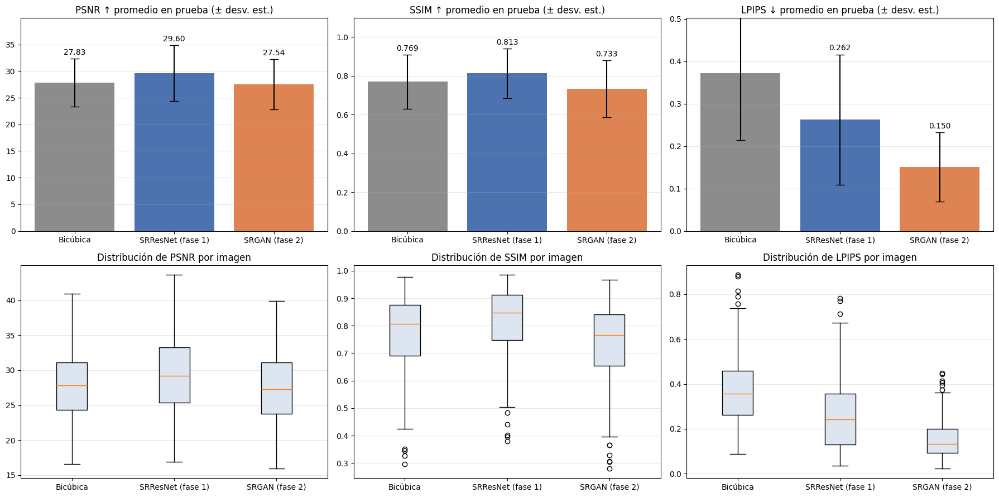

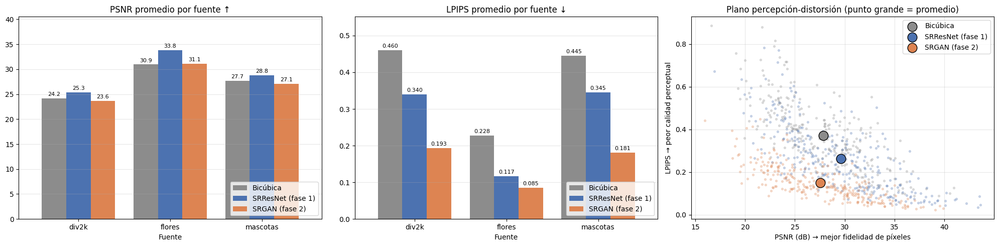

In [ ]:
# Gráficas de los resultados en el conjunto de prueba
metodos = list(res)
colores = ["#8C8C8C", "#4C72B0", "#DD8452"]
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
for j, (met, fmt, mejor) in enumerate([("PSNR", "{:.2f}", "↑"), ("SSIM", "{:.3f}", "↑"), ("LPIPS", "{:.3f}", "↓")]):
    medias = [np.mean(res[m][met]) for m in metodos]
    barras = ax[0, j].bar(metodos, medias, yerr=[np.std(res[m][met]) for m in metodos], capsize=6, color=colores)
    ax[0, j].bar_label(barras, labels=[fmt.format(v) for v in medias], padding=3)
    ax[0, j].set_title(f"{met} {mejor} promedio en prueba (± desv. est.)")
    ax[0, j].set_ylim(0, max(medias) * 1.35); ax[0, j].grid(axis="y", alpha=0.3)
    ax[1, j].boxplot([res[m][met] for m in metodos], tick_labels=metodos, patch_artist=True,
                     boxprops=dict(facecolor="#DDE6F0"))
    ax[1, j].set_title(f"Distribución de {met} por imagen"); ax[1, j].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

# Por fuente y plano percepción-distorsión
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, met, titulo in [(ax[0], "PSNR (dB)", "PSNR promedio por fuente ↑"), (ax[1], "LPIPS", "LPIPS promedio por fuente ↓")]:
    pf = por_fuente[met].reindex(list(FUENTES))[metodos]
    pf.plot.bar(ax=a, color=colores, rot=0, width=0.8)
    for c in a.containers:
        a.bar_label(c, fmt="%.1f" if met.startswith("PSNR") else "%.3f", fontsize=8, padding=2)
    a.set_title(titulo); a.set_ylim(0, pf.values.max() * 1.2); a.grid(axis="y", alpha=0.3); a.legend(loc="lower right")
for m, col in zip(metodos, colores):
    ax[2].scatter(res[m]["PSNR"], res[m]["LPIPS"], s=8, alpha=0.25, color=col)
    ax[2].scatter(np.mean(res[m]["PSNR"]), np.mean(res[m]["LPIPS"]), s=180, color=col, edgecolor="k", label=m, zorder=3)
ax[2].set_xlabel("PSNR (dB) → mejor fidelidad de píxeles"); ax[2].set_ylabel("LPIPS → peor calidad perceptual")
ax[2].set_title("Plano percepción-distorsión (punto grande = promedio)"); ax[2].legend(); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

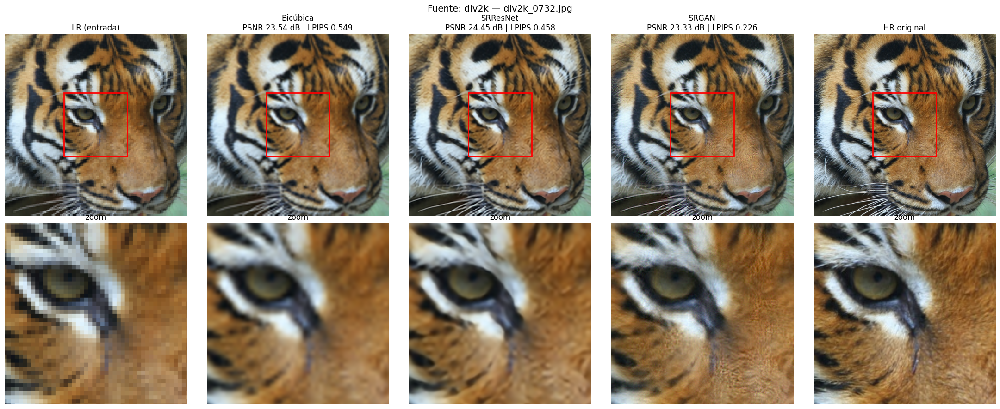

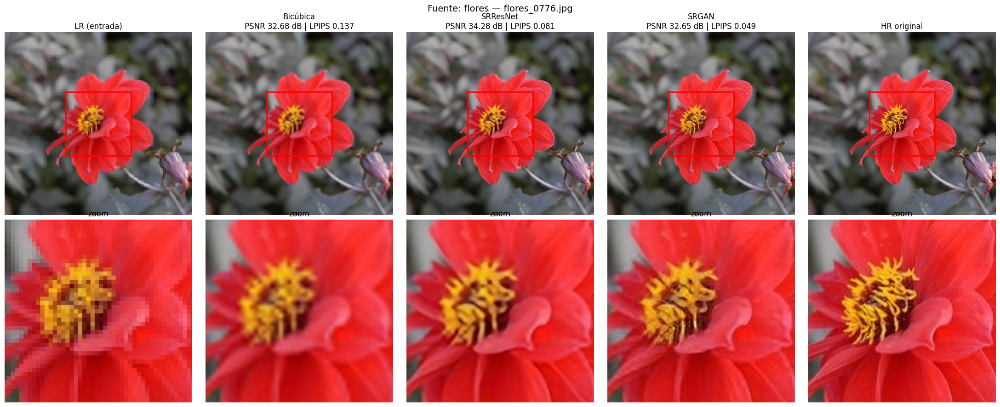

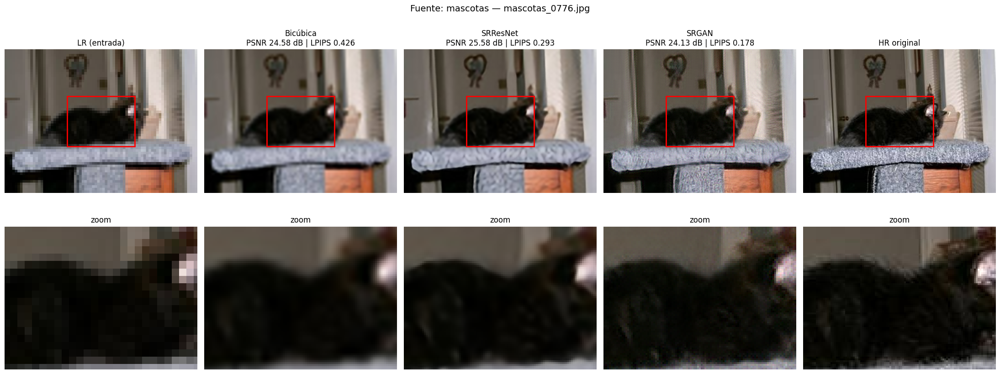

In [ ]:
# Comparación visual con acercamiento (zoom): mismas imágenes y mismo recorte para los tres métodos
def comparar(ruta, zoom=0.35, titulo=None, zoom_en="centro"):
    lr, hr = par_prueba(ruta)
    lr, hr = lr[None], hr[None]
    imgs = {"LR (entrada)": tf.image.resize(lr, [int(d) for d in hr.shape[1:3]], method="nearest")[0],
            "Bicúbica": bicubica(lr, hr.shape[1:3])[0],
            "SRResNet": predecir(srresnet, lr)[0],
            "SRGAN": predecir(srgan, lr)[0],
            "HR original": hr[0]}
    H, W = hr.shape[1:3]
    zh, zw = int(H * zoom), int(W * zoom)
    if zoom_en == "diferencia":
        # región donde SRGAN y SRResNet difieren más (texturas añadidas o artefactos)
        dif = tf.reduce_mean(tf.abs(imgs["SRGAN"] - imgs["SRResNet"]), axis=-1)[None, :, :, None]
        mapa = tf.nn.avg_pool2d(dif, (zh, zw), strides=8, padding="VALID")[0, :, :, 0].numpy()
        iy, ix = np.unravel_index(np.argmax(mapa), mapa.shape)
        y0, x0 = iy * 8, ix * 8
    else:
        y0, x0 = (H - zh) // 2, (W - zw) // 2
    fig, ax = plt.subplots(2, 5, figsize=(22, 9))
    for j, (nombre, im) in enumerate(imgs.items()):
        im = np.clip(np.array(im), 0, 1)
        txt = nombre
        if nombre not in ("LR (entrada)", "HR original"):
            txt += f"\nPSNR {float(tf.image.psnr(hr[0], im, 1.0)):.2f} dB | LPIPS {calcular_lpips(hr, im[None]):.3f}"
        ax[0, j].imshow(im); ax[0, j].set_title(txt); ax[0, j].axis("off")
        ax[0, j].add_patch(plt.Rectangle((x0, y0), zw, zh, fill=False, ec="red", lw=2))
        ax[1, j].imshow(im[y0:y0 + zh, x0:x0 + zw]); ax[1, j].set_title("zoom"); ax[1, j].axis("off")
    plt.suptitle(titulo or os.path.basename(ruta), fontsize=14)
    plt.tight_layout(); plt.show()

# Una imagen de prueba de cada fuente del dataset
for f in FUENTES:
    r = next(r for r in rutas_test if fuente_de(r) == f)
    comparar(r, titulo=f"Fuente: {f} — {os.path.basename(r)}")

### Análisis cualitativo: dónde mejora SRGAN y dónde falla

Para no elegir ejemplos a mano, los casos se seleccionan automáticamente en el conjunto de prueba con la diferencia de LPIPS entre SRGAN y SRResNet en cada imagen, $\Delta_{LPIPS} = \text{LPIPS}_{SRGAN} - \text{LPIPS}_{SRResNet}$:
- **Mejores casos** (Δ más negativo): SRGAN produce una imagen perceptualmente más cercana al original que SRResNet.
- **Peores casos** (Δ más positivo): SRGAN se aleja del original; suelen aparecer texturas inventadas o artefactos.

El recuadro de zoom se ubica automáticamente donde SRGAN y SRResNet más difieren.

SRGAN tiene menor LPIPS que SRResNet en 95.4 % de las imágenes de prueba (ΔLPIPS promedio -0.1117, ΔPSNR promedio -2.06 dB)

Por fuente:


,ΔLPIPS promedio,% imágenes donde SRGAN tiene menor LPIPS,ΔPSNR promedio (dB)
fuente,,,
div2k,-0.1465,100.0,-1.6943
flores,-0.0317,87.0,-2.6906
mascotas,-0.1637,100.0,-1.7259


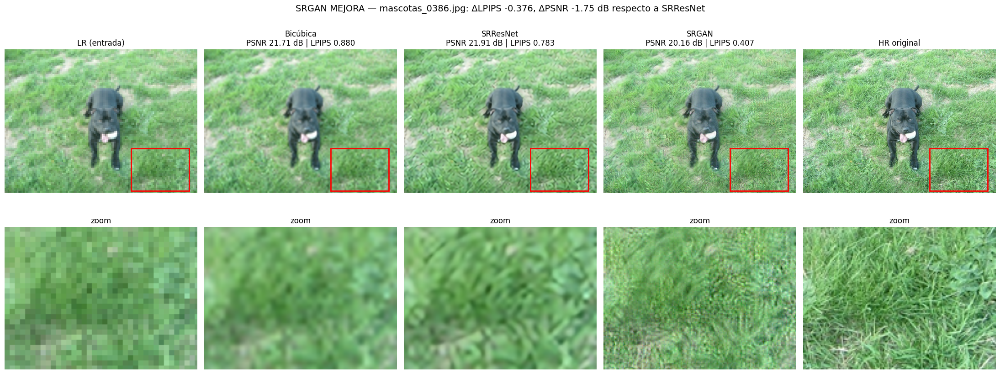

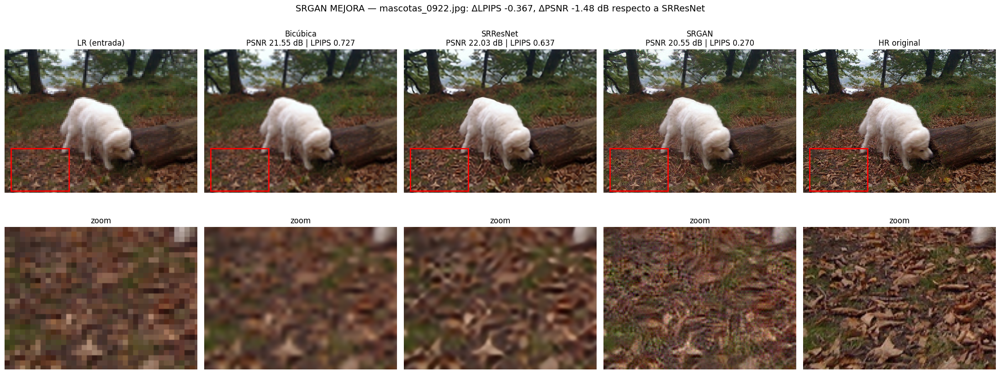

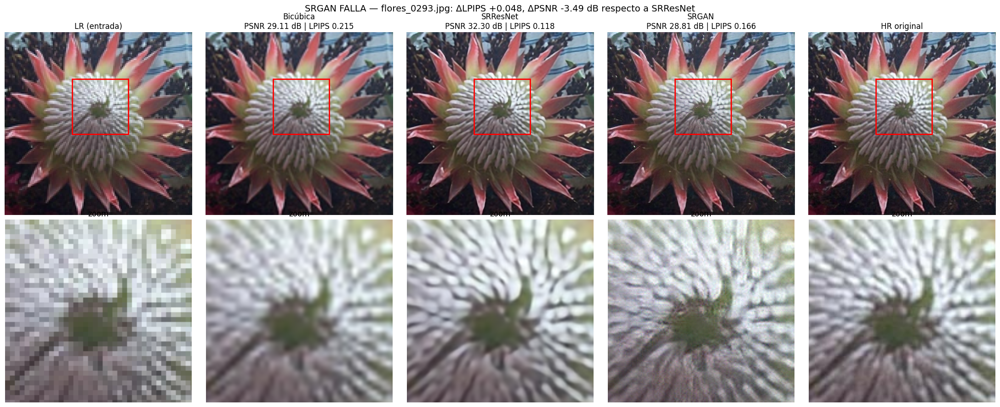

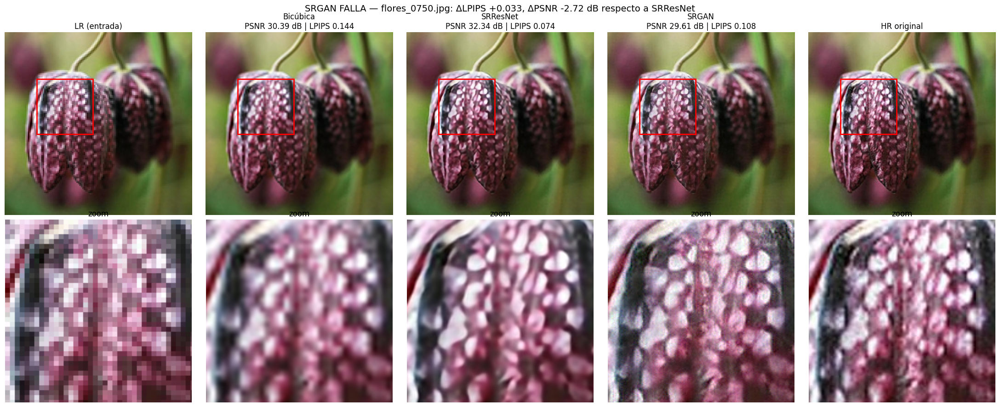

In [ ]:
d_lpips = np.array(res["SRGAN (fase 2)"]["LPIPS"]) - np.array(res["SRResNet (fase 1)"]["LPIPS"])
d_psnr  = np.array(res["SRGAN (fase 2)"]["PSNR"]) - np.array(res["SRResNet (fase 1)"]["PSNR"])
print(f"SRGAN tiene menor LPIPS que SRResNet en {100 * np.mean(d_lpips < 0):.1f} % de las imágenes de prueba "
      f"(ΔLPIPS promedio {d_lpips.mean():+.4f}, ΔPSNR promedio {d_psnr.mean():+.2f} dB)")
casos = pd.DataFrame({"imagen": [os.path.basename(r) for r in rutas_test], "fuente": fuentes_test,
                      "ΔLPIPS (SRGAN − SRResNet)": d_lpips, "ΔPSNR (dB)": d_psnr})
print("\nPor fuente:")
display(casos.groupby("fuente").agg(**{
    "ΔLPIPS promedio": ("ΔLPIPS (SRGAN − SRResNet)", "mean"),
    "% imágenes donde SRGAN tiene menor LPIPS": ("ΔLPIPS (SRGAN − SRResNet)", lambda x: 100 * np.mean(x < 0)),
    "ΔPSNR promedio (dB)": ("ΔPSNR (dB)", "mean")}).reindex(list(FUENTES)).round(4))

orden = np.argsort(d_lpips)
for etiqueta, idx in [("SRGAN MEJORA", orden[:2]), ("SRGAN FALLA", orden[::-1][:2])]:
    for i in idx:
        comparar(rutas_test[i], zoom=0.3, zoom_en="diferencia",
                 titulo=f"{etiqueta} — {os.path.basename(rutas_test[i])}: "
                        f"ΔLPIPS {d_lpips[i]:+.3f}, ΔPSNR {d_psnr[i]:+.2f} dB respecto a SRResNet")

**Interpretación.**
- **Dónde mejora SRGAN:** los mejores casos son fotos de mascotas con fondos de texturas naturales densas e irregulares (pasto, hojarasca). La bicúbica y SRResNet las reducen a manchas borrosas, mientras que SRGAN reconstruye briznas y hojas con una estadística muy parecida a la del original: el LPIPS baja ≈ 0.37 respecto a SRResNet (por ejemplo, de 0.78 a 0.41), aunque el PSNR cae ≈ 1.5–1.8 dB porque los detalles generados no quedan exactamente en la misma posición que los reales.
- **Dónde falla:** los peores casos son flores con estructuras finas y regulares (los filamentos radiales de una protea, el patrón ajedrezado de una fritillaria). SRGAN añade un grano de alta frecuencia que no sigue el patrón ordenado del original, y la versión suave de SRResNet resulta más parecida. Aun así, el aumento de LPIPS es pequeño (≤ 0.05), mientras el PSNR cae ≈ 2.7–3.5 dB.
- En conjunto, SRGAN reduce el LPIPS en el 95.4 % de las imágenes de prueba (100 % en DIV2K y en mascotas); las excepciones se concentran en las flores (87 %), con fondos lisos y detalles regulares donde inventar textura no aporta.

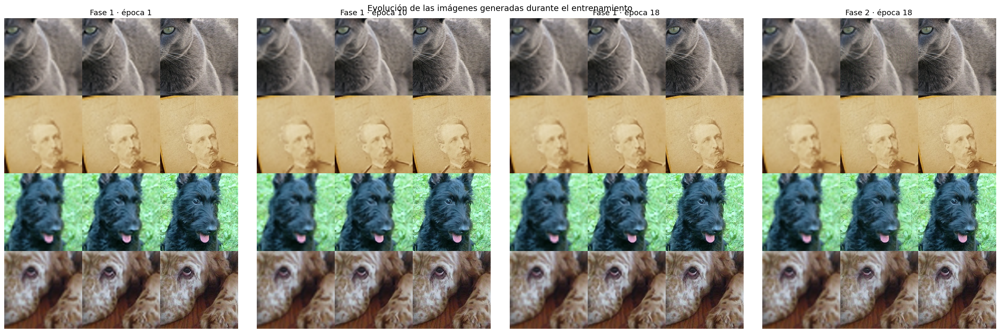

In [ ]:
# Evolución del generador durante el entrenamiento (en cada imagen, columnas: bicúbica | modelo | HR real)
m1 = sorted(glob.glob(os.path.join(CKPT_DIR, "muestras", "fase1_ep*.png")))
m2 = sorted(glob.glob(os.path.join(CKPT_DIR, "muestras", "fase2_ep*.png")))
sel = [(m1[0], "Fase 1 · época 1"), (m1[len(m1) // 2], f"Fase 1 · época {len(m1) // 2 + 1}"),
       (m1[-1], f"Fase 1 · época {len(m1)}"), (m2[-1], f"Fase 2 · época {len(m2)}")]
fig, ax = plt.subplots(1, len(sel), figsize=(6 * len(sel), 8))
for a, (ruta, titulo) in zip(ax, sel):
    a.imshow(plt.imread(ruta)); a.set_title(titulo, fontsize=13); a.axis("off")
plt.suptitle("Evolución de las imágenes generadas durante el entrenamiento", fontsize=14)
plt.tight_layout(); plt.show()

### Rendimiento computacional

Costo de los modelos: número de parámetros, tiempo de entrenamiento por época e iteración, tiempo de inferencia y memoria de GPU usada al procesar imágenes de distintos tamaños. SRResNet y SRGAN comparten la arquitectura del generador, por lo que su costo de inferencia es idéntico; solo cambian los pesos.

In [ ]:
gpus = tf.config.list_physical_devices("GPU")
dispositivo = tf.config.experimental.get_device_details(gpus[0]).get("device_name", "GPU") if gpus else "CPU"
print("Dispositivo:", dispositivo)

def tamano_mb(modelo):
    return modelo.count_params() * 4 / 1024 ** 2          # float32

parametros = pd.DataFrame({
    "Generador (SRResNet / SRGAN)": {"Parámetros": generador.count_params(), "Tamaño float32 (MB)": tamano_mb(generador)},
    "Discriminador (solo entrenamiento)": {"Parámetros": discriminador.count_params(), "Tamaño float32 (MB)": tamano_mb(discriminador)},
    "VGG19 hasta block5_conv4 (congelada)": {"Parámetros": extractor_vgg.count_params(), "Tamaño float32 (MB)": tamano_mb(extractor_vgg)},
}).T
parametros["Parámetros"] = parametros["Parámetros"].astype(int)
display(parametros.round(2))

# Tiempo de entrenamiento (mediana por época: robusta frente a épocas atípicas, p. ej. una ejecutada sin GPU)
entrenamiento = pd.DataFrame({
    f: {"Épocas": len(h), "Iteraciones": int(len(h) * PASOS_POR_EPOCA),
        "Mediana por época (s)": h["tiempo_s"].median(),
        "Por iteración (ms)": h["tiempo_s"].median() / PASOS_POR_EPOCA * 1000,
        "Total estimado en GPU (min)": h["tiempo_s"].median() * len(h) / 60}
    for f, h in [("Fase 1 (SRResNet)", h1), ("Fase 2 (SRGAN)", h2)]}).T
entrenamiento[["Épocas", "Iteraciones"]] = entrenamiento[["Épocas", "Iteraciones"]].astype(int)
print("\nTiempo de entrenamiento (GPU T4):")
display(entrenamiento.round(1))

def medir_ms(fn, x, repeticiones=20):
    np.asarray(fn(x))                                    # calentamiento (compilación)
    t0 = time.perf_counter()
    for _ in range(repeticiones):
        y = fn(x)
    np.asarray(y)                                        # espera a que la GPU termine
    return (time.perf_counter() - t0) / repeticiones * 1000

filas = []
for lado in (64, 128, 256):
    x = tf.random.uniform((1, lado, lado, 3))
    for nombre, fn in [("Bicúbica", lambda z: bicubica(z, (lado * ESCALA, lado * ESCALA))),
                       ("Generador (SRResNet / SRGAN)", lambda z: srgan(z, training=False))]:
        if gpus:
            tf.config.experimental.reset_memory_stats("GPU:0")
            antes = tf.config.experimental.get_memory_info("GPU:0")["current"]
        ms = medir_ms(fn, x)
        fila = {"Entrada LR": f"{lado}×{lado}", "Salida SR": f"{lado * ESCALA}×{lado * ESCALA}",
                "Método": nombre, "Tiempo (ms/imagen)": ms}
        if gpus:
            fila["Memoria GPU adicional (MB)"] = (tf.config.experimental.get_memory_info("GPU:0")["peak"] - antes) / 1024 ** 2
        filas.append(fila)
print(f"\nInferencia en {dispositivo} (promedio de 20 repeticiones, lote 1):")
display(pd.DataFrame(filas).set_index(["Entrada LR", "Salida SR", "Método"]).round(1))

Dispositivo: Tesla T4


,Parámetros,Tamaño float32 (MB)
Generador (SRResNet / SRGAN),1546435,5.90
Discriminador (solo entrenamiento),23569217,89.91
VGG19 hasta block5_conv4 (congelada),20024384,76.39



Tiempo de entrenamiento (GPU T4):


,Épocas,Iteraciones,Mediana por época (s),Por iteración (ms),Total estimado en GPU (min)
Fase 1 (SRResNet),18,10080,66.9,119.4,20.1
Fase 2 (SRGAN),18,10080,180.5,322.3,54.1



Inferencia en Tesla T4 (promedio de 20 repeticiones, lote 1):


Tiempo (ms/imagen)  \
Entrada LR Salida SR Método                                             
64×64      256×256   Bicúbica                                     2.7   
                     Generador (SRResNet / SRGAN)               134.7   
128×128    512×512   Bicúbica                                     4.1   
                     Generador (SRResNet / SRGAN)               143.1   
256×256    1024×1024 Bicúbica                                     9.6   
                     Generador (SRResNet / SRGAN)               260.2   

                                                   Memoria GPU adicional (MB)  
Entrada LR Salida SR Método                                                    
64×64      256×256   Bicúbica                                             3.1  
                     Generador (SRResNet / SRGAN)                       199.0  
128×128    512×512   Bicúbica                                            15.0  
                     Generador (SRResNet / SRGAN)                       748.6  
256×256    1024×1024 Bicúbica                                            57.3  
                     Generador (SRResNet / SRGAN)                      2697.2

### Guardar el modelo final
Se guarda el generador completo en formato `.keras` (arquitectura + pesos) en la carpeta de checkpoints.

In [ ]:
srgan.save(os.path.join(CKPT_DIR, "srgan_generador_x4.keras"))
srresnet.save(os.path.join(CKPT_DIR, "srresnet_generador_x4.keras"))
print("Modelos guardados en", CKPT_DIR)
# Para cargarlo después:  modelo = keras.models.load_model(ruta, custom_objects={"PixelShuffle": PixelShuffle, "AmpliacionBicubica": AmpliacionBicubica})

Modelos guardados en /content/drive/MyDrive/srgan_resultados_v2


## 8. Uso del modelo con imágenes nuevas

Hay dos modos:
- `"simulado"`: la imagen se reduce ×4 y el modelo la reconstruye, para comparar con el original (permite medir PSNR).
- `"real"`: la imagen se toma tal cual como entrada y se **amplía ×4** (uso real: mejorar una foto pequeña). Se procesa por bloques (*tiles*) para no agotar la memoria de la GPU con imágenes grandes.

Saving gato_prueba.jpg to gato_prueba.jpg


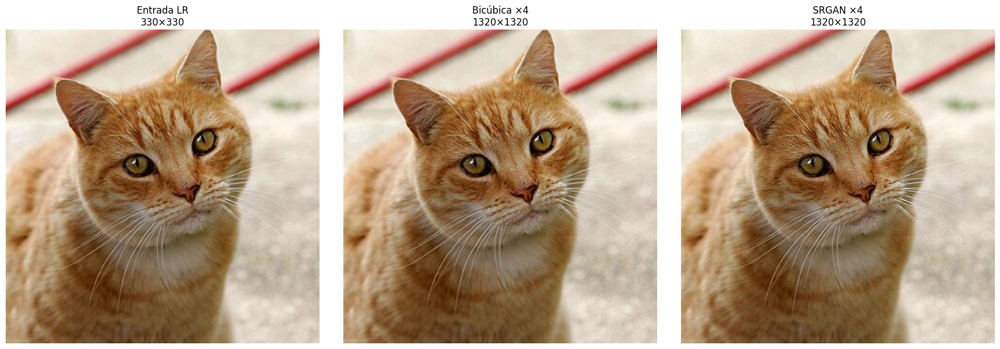

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
def super_resolver(modelo, lr, tile=128, solape=16):
    """Aplica el generador por bloques solapados. lr: array (H, W, 3) en [0,1]."""
    H, W, _ = lr.shape
    salida = np.zeros((H * ESCALA, W * ESCALA, 3), np.float32)
    for y in range(0, H, tile):
        for x in range(0, W, tile):
            y0, x0 = max(y - solape, 0), max(x - solape, 0)
            y1, x1 = min(y + tile + solape, H), min(x + tile + solape, W)
            sr = modelo(lr[None, y0:y1, x0:x1], training=False)[0].numpy()
            th, tw = (min(y + tile, H) - y) * ESCALA, (min(x + tile, W) - x) * ESCALA
            oy, ox = (y - y0) * ESCALA, (x - x0) * ESCALA
            salida[y * ESCALA:y * ESCALA + th, x * ESCALA:x * ESCALA + tw] = sr[oy:oy + th, ox:ox + tw]
    return np.clip(salida, 0, 1)

MODO = "real"   # "real" | "simulado"

from google.colab import files
subidas = files.upload()
for nombre in subidas:
    img = np.asarray(ImageOps.exif_transpose(Image.open(nombre)).convert("RGB"), np.float32) / 255.0
    if MODO == "simulado":
        h, w = img.shape[0] // ESCALA * ESCALA, img.shape[1] // ESCALA * ESCALA
        hr = img[:h, :w]
        lr = degradar(tf.constant(hr), h // ESCALA, w // ESCALA).numpy()
    else:
        lr, hr = img, None
    sr = super_resolver(srgan, lr)
    bic = bicubica(lr[None], sr.shape[:2])[0].numpy()

    paneles = [("Entrada LR", lr), ("Bicúbica ×4", bic), ("SRGAN ×4", sr)] + ([("Original", hr)] if hr is not None else [])
    fig, ax = plt.subplots(1, len(paneles), figsize=(6 * len(paneles), 6))
    for a, (t, im) in zip(ax, paneles):
        if hr is not None and t in ("Bicúbica ×4", "SRGAN ×4"):
            t += f"  (PSNR {float(tf.image.psnr(hr, im, 1.0)):.2f} dB)"
        a.imshow(im); a.set_title(f"{t}\n{im.shape[1]}×{im.shape[0]}"); a.axis("off")
    plt.tight_layout(); plt.show()

    salida = f"SR_x{ESCALA}_{os.path.splitext(nombre)[0]}.png"
    Image.fromarray((sr * 255).round().astype(np.uint8)).save(salida)
    files.download(salida)

## 9. Conclusiones

### Datos y entrenamiento
- Se construyó un dataset propio de 2 800 imágenes combinando DIV2K (escenas 2K), Oxford 102 Flowers y Oxford-IIIT Pet, con división 80/10/10 estratificada por fuente.
- El modelo se entrenó desde cero en una sola ejecución, con semillas fijas y operaciones deterministas, y con la salida del generador acotada a [0, 1] también durante el entrenamiento.
- **Fase 1 (SRResNet, 18 épocas):** el PSNR de validación subió de forma sostenida de 27.41 a **28.09 dB** en la mejor época (17; la última quedó en 28.08 dB), frente a 26.49 dB de la bicúbica. Las pérdidas de entrenamiento y validación bajaron juntas, sin sobreajuste; en las últimas épocas la curva ya se aplana.
- **Fase 2 (SRGAN, 18 épocas):** el entrenamiento fue estable (sin divergencia ni colapso): $\mathcal{L}_G$ se mantuvo entre 0.152 y 0.161 y la pérdida VGG de validación bajó de 0.219 a 0.182. El discriminador terminó dominando ($D(\text{real}) \approx 0.97$, $D(\text{falso}) \approx 0.03$), lo que la forma no saturante de la pérdida adversarial y su peso de $10^{-3}$ (≈ 5 % de $\mathcal{L}_G$) toleran sin desestabilizar al generador. Bajar la tasa de aprendizaje a $10^{-5}$ redujo la variación del PSNR de validación de 0.21 a 0.08 dB.

### Fidelidad de píxeles (PSNR, SSIM)
- **SRResNet** es el mejor método en fidelidad: **29.60 ± 5.21 dB / SSIM 0.813 ± 0.128** en prueba, **+1.76 dB** sobre la bicúbica (27.83 dB / 0.769), superándola en el **100 %** de las 280 imágenes y en las tres fuentes (DIV2K 25.33 vs 24.16 dB, flores 33.79 vs 30.94, mascotas 28.81 vs 27.67).
- **SRGAN** obtiene 27.54 ± 4.69 dB / 0.733: 0.30 dB por debajo de la bicúbica y 2.06 dB por debajo de SRResNet. Es lo esperado: minimizar el MSE equivale a maximizar el PSNR, y SRGAN deja de optimizar principalmente el MSE.

### Calidad perceptual (LPIPS y análisis visual)
- **SRGAN** es claramente el mejor método perceptual: **LPIPS 0.151 ± 0.082**, frente a 0.262 ± 0.154 de SRResNet (−43 %) y 0.372 ± 0.158 de la bicúbica, con menor LPIPS que SRResNet en el **95.4 %** de las imágenes.
- La mejora perceptual es mayor en texturas complejas (mascotas: ΔLPIPS −0.164; DIV2K: −0.147) que en flores (−0.032), donde SRResNet ya obtenía un LPIPS bajo (0.117) por sus fondos lisos.
- Visualmente, SRGAN recupera pasto, hojarasca y follaje que SRResNet suaviza; sus fallas son texturas inventadas sobre patrones finos y regulares (sección de análisis cualitativo).
- Ningún método domina en ambas dimensiones: SRResNet minimiza la distorsión y SRGAN la distancia perceptual. Es el **compromiso percepción-distorsión** (Blau & Michaeli, 2018), visible en el plano PSNR–LPIPS.

### Eficiencia computacional
- Ambos modelos usan el mismo generador: **1.55 M de parámetros (5.9 MB)**, con idéntico costo de inferencia. El discriminador (23.6 M) y la VGG19 (20.0 M) solo se usan durante el entrenamiento.
- Entrenamiento en GPU T4: 67 s por época en la fase 1 (119 ms por iteración) y 181 s en la fase 2 (322 ms por iteración, ≈ 2.7× más costosa por el discriminador y la VGG); en total ≈ 75 min. Las operaciones deterministas hacen el entrenamiento algo más lento a cambio de resultados repetibles.
- Inferencia en GPU T4 (lote 1): ≈ 135 ms para una salida de 256×256, 143 ms para 512×512 y 260 ms para 1024×1024, frente a 3–10 ms de la bicúbica; la memoria adicional crece de ≈ 0.2 GB a ≈ 2.7 GB con el tamaño de la imagen.

### Limitaciones
- SRGAN puede **inventar texturas** que no existen en la imagen original (alucinaciones), sobre todo en patrones finos y regulares; no es adecuado cuando se requiere fidelidad exacta (por ejemplo, imágenes médicas o forenses).
- El modelo de degradación es solo la reducción bicúbica: con fotos reales (ruido, desenfoque, compresión JPEG) el desempeño disminuye.
- Dataset pequeño (2 240 imágenes de entrenamiento) y entrenamiento corto (≈ 1 % de las iteraciones del artículo original).
- No hubo evaluación con personas (MOS); LPIPS es una aproximación automática a la percepción humana. No se realizó un estudio de ablación.

### Trabajo futuro
- Estudio de ablación: sin aprendizaje residual global, con Batch Normalization, sin el término MSE y sin pérdida adversarial, para medir el aporte de cada componente.
- Entrenar más épocas y con más datos (por ejemplo, DIV2K completo + Flickr2K).
- Incorporar las mejoras de ESRGAN (bloques RRDB, discriminador relativista, pérdida VGG antes de la activación) y normalización espectral en el discriminador para equilibrar el entrenamiento adversarial.
- Entrenar con degradaciones realistas (`DEGRADACION_REALISTA = True`, estilo Real-ESRGAN) y validar con un estudio de opinión (MOS).

### Referencias
- Ledig, C. et al. (2017). *Photo-Realistic Single Image Super-Resolution Using a Generative Adversarial Network*. CVPR.
- Lim, B. et al. (2017). *Enhanced Deep Residual Networks for Single Image Super-Resolution (EDSR)*. CVPRW.
- Wang, X. et al. (2018). *ESRGAN: Enhanced Super-Resolution Generative Adversarial Networks*. ECCVW.
- Kim, J., Lee, J. K. & Lee, K. M. (2016). *Accurate Image Super-Resolution Using Very Deep Convolutional Networks (VDSR)*. CVPR.
- Shi, W. et al. (2016). *Real-Time Single Image and Video Super-Resolution Using an Efficient Sub-Pixel CNN*. CVPR.
- Blau, Y. & Michaeli, T. (2018). *The Perception-Distortion Tradeoff*. CVPR.
- Zhang, R. et al. (2018). *The Unreasonable Effectiveness of Deep Features as a Perceptual Metric (LPIPS)*. CVPR.
- Goodfellow, I. et al. (2014). *Generative Adversarial Nets*. NeurIPS.
- Agustsson, E. & Timofte, R. (2017). *NTIRE 2017 Challenge on Single Image Super-Resolution: Dataset and Study (DIV2K)*. CVPRW.
- Nilsback, M.-E. & Zisserman, A. (2008). *Automated Flower Classification over a Large Number of Classes (Oxford 102 Flowers)*. ICVGIP.
- Parkhi, O. M., Vedaldi, A., Zisserman, A. & Jawahar, C. V. (2012). *Cats and Dogs (Oxford-IIIT Pet)*. CVPR.